In [39]:
import networkx as nx
import matplotlib.pyplot as plt
import math

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["font.size"] = 11

def draw_simple(G, title, pos=None, node_size=800, with_labels=True, labels=None):
    if pos is None:
        pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(8, 6))
    nx.draw(
        G,
        pos,
        with_labels=with_labels if labels is None else False,
        node_size=node_size,
        width=1.6,
        arrows=G.is_directed(),
        arrowsize=18 if G.is_directed() else 10
    )
    if labels is not None:
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=10)
    plt.title(title)
    plt.axis("off")
    plt.show()

def simple_projection(G):
    H = nx.Graph()
    H.add_nodes_from(G.nodes())
    H.add_edges_from((u, v) for u, v in G.edges() if u != v)
    return H

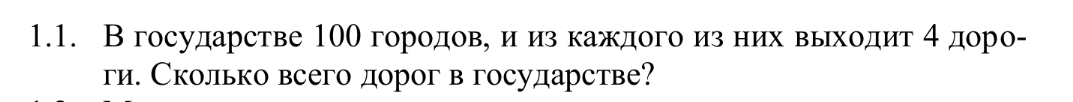

Количество городов: 100
Количество дорог: 200
Все вершины имеют степень 4: True
Ответ: 200 дорог


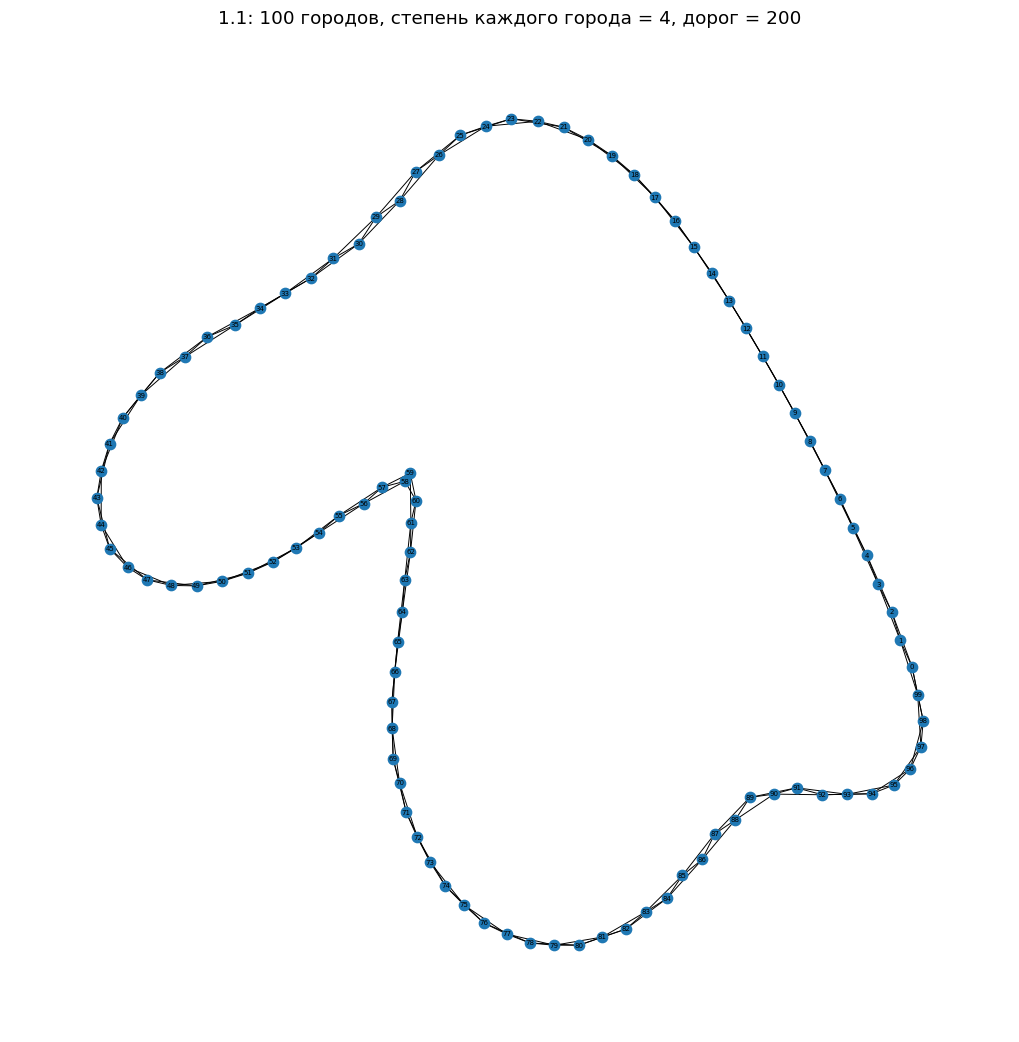

In [40]:
G11 = nx.circulant_graph(100, [1, 2])

print("Количество городов:", G11.number_of_nodes())
print("Количество дорог:", G11.number_of_edges())
print("Все вершины имеют степень 4:", all(d == 4 for _, d in G11.degree()))
print("Ответ:", G11.number_of_edges(), "дорог")


plt.figure(figsize=(10, 10))
nx.draw(
    G11,
    node_size=55,
    width=0.7,
    with_labels=True,
    font_size=5
)
plt.title("1.1: 100 городов, степень каждого города = 4, дорог = 200")
plt.axis("off")
plt.show()

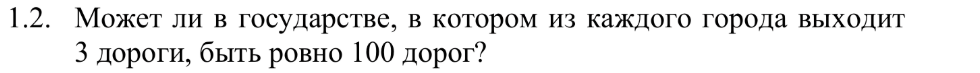

По лемме о рукопожатиях:
3 * n = 2 * 100
n = 66.66666666666667
n целое: False
Ответ: нет, такой граф существовать не может.

Ближайшие 3-регулярные варианты:
66 городов -> 99 дорог
68 городов -> 102 дорог


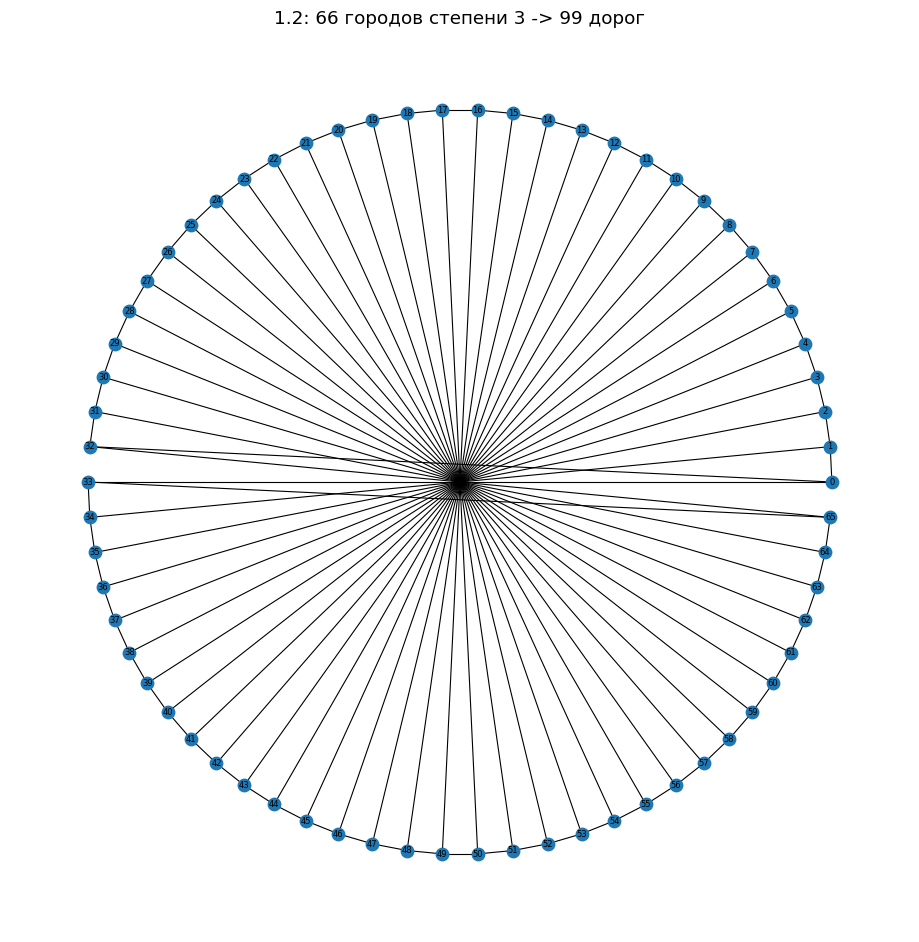

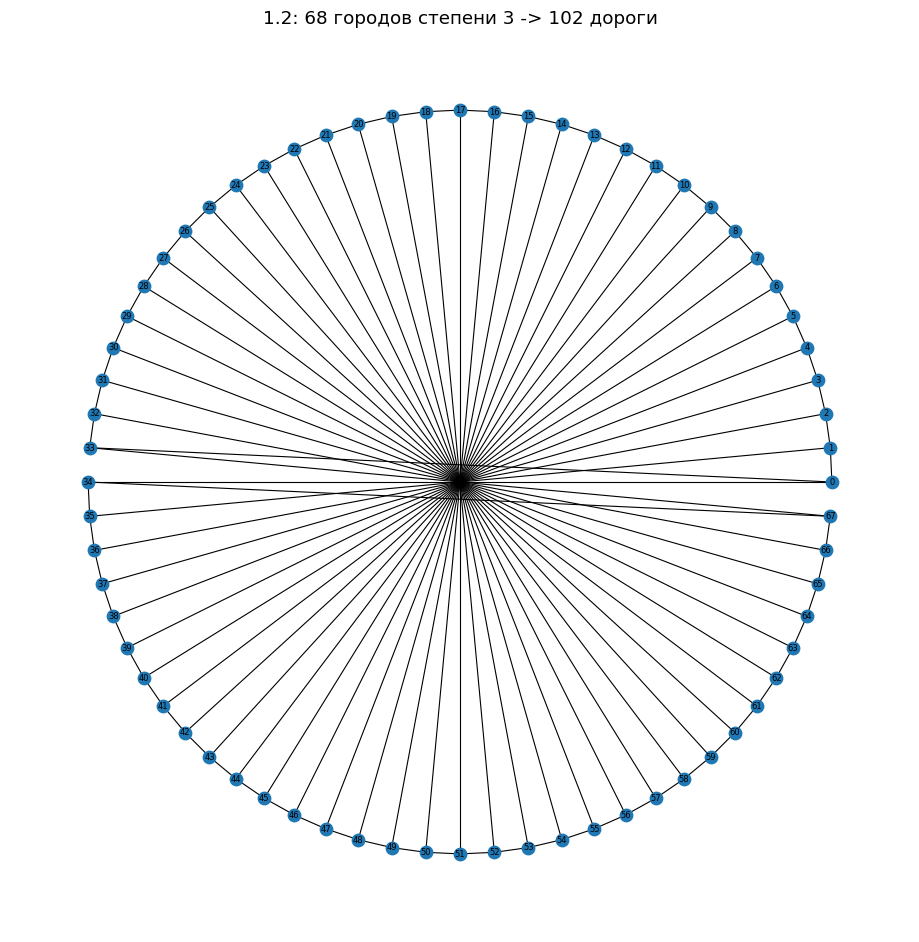

In [41]:
roads = 100
degree = 3
required_vertices = 2 * roads / degree

print("По лемме о рукопожатиях:")
print(f"3 * n = 2 * {roads}")
print("n =", required_vertices)
print("n целое:", required_vertices.is_integer())
print("Ответ: нет, такой граф существовать не может.")

G12_66 = nx.circular_ladder_graph(33)
G12_68 = nx.circular_ladder_graph(34)

print("\nБлижайшие 3-регулярные варианты:")
print("66 городов ->", G12_66.number_of_edges(), "дорог")
print("68 городов ->", G12_68.number_of_edges(), "дорог")

plt.figure(figsize=(9, 9))
nx.draw(
    G12_66,
    nx.circular_layout(G12_66),
    node_size=80,
    width=0.8,
    with_labels=True,
    font_size=6
)
plt.title("1.2: 66 городов степени 3 -> 99 дорог")
plt.axis("off")
plt.show()

plt.figure(figsize=(9, 9))
nx.draw(
    G12_68,
    nx.circular_layout(G12_68),
    node_size=80,
    width=0.8,
    with_labels=True,
    font_size=6
)
plt.title("1.2: 68 городов степени 3 -> 102 дороги")
plt.axis("off")
plt.show()

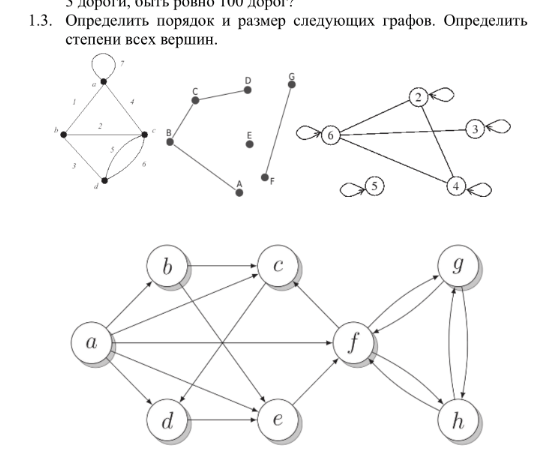

Граф 1
Порядок: 4
Размер: 7
Степени: {'a': 4, 'b': 3, 'c': 4, 'd': 3}


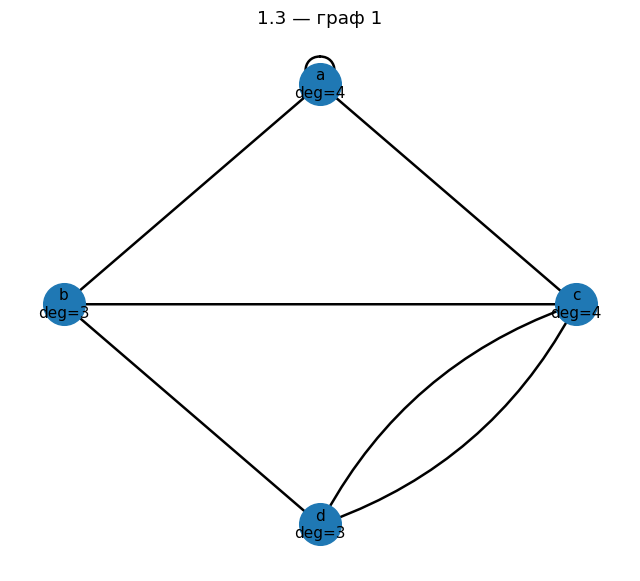


Граф 2
Порядок: 7
Размер: 4
Степени: {'A': 1, 'B': 2, 'C': 2, 'D': 1, 'E': 0, 'F': 1, 'G': 1}


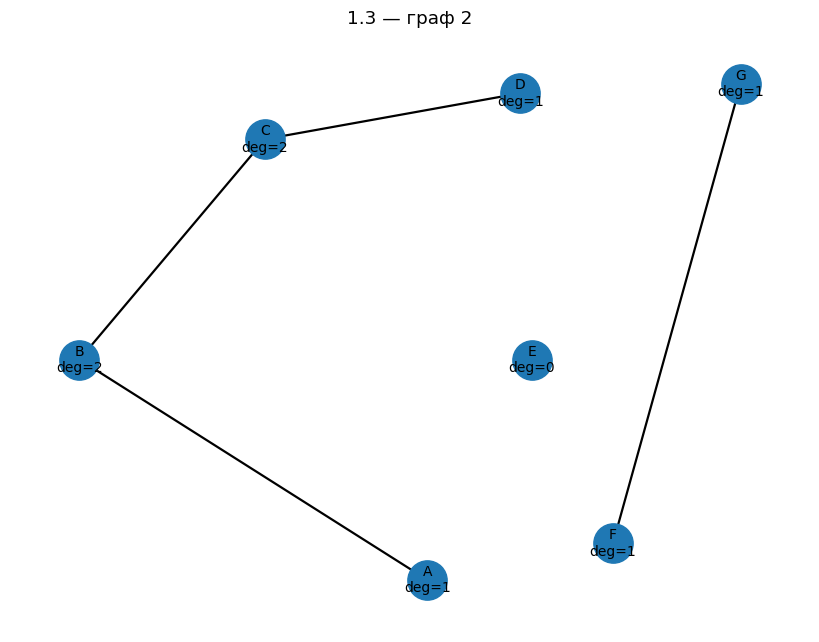


Граф 3
Порядок: 5
Размер: 9
Степени: {2: 4, 3: 3, 4: 4, 5: 2, 6: 5}


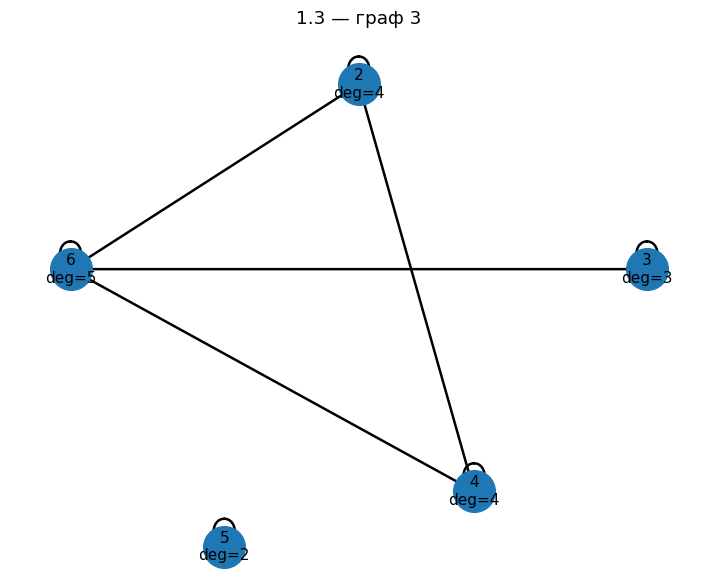


Граф 4
Порядок: 8
Размер: 17
a: in=0, out=5, degree=5
b: in=1, out=2, degree=3
c: in=3, out=1, degree=4
d: in=2, out=1, degree=3
e: in=3, out=1, degree=4
f: in=4, out=3, degree=7
g: in=2, out=2, degree=4
h: in=2, out=2, degree=4


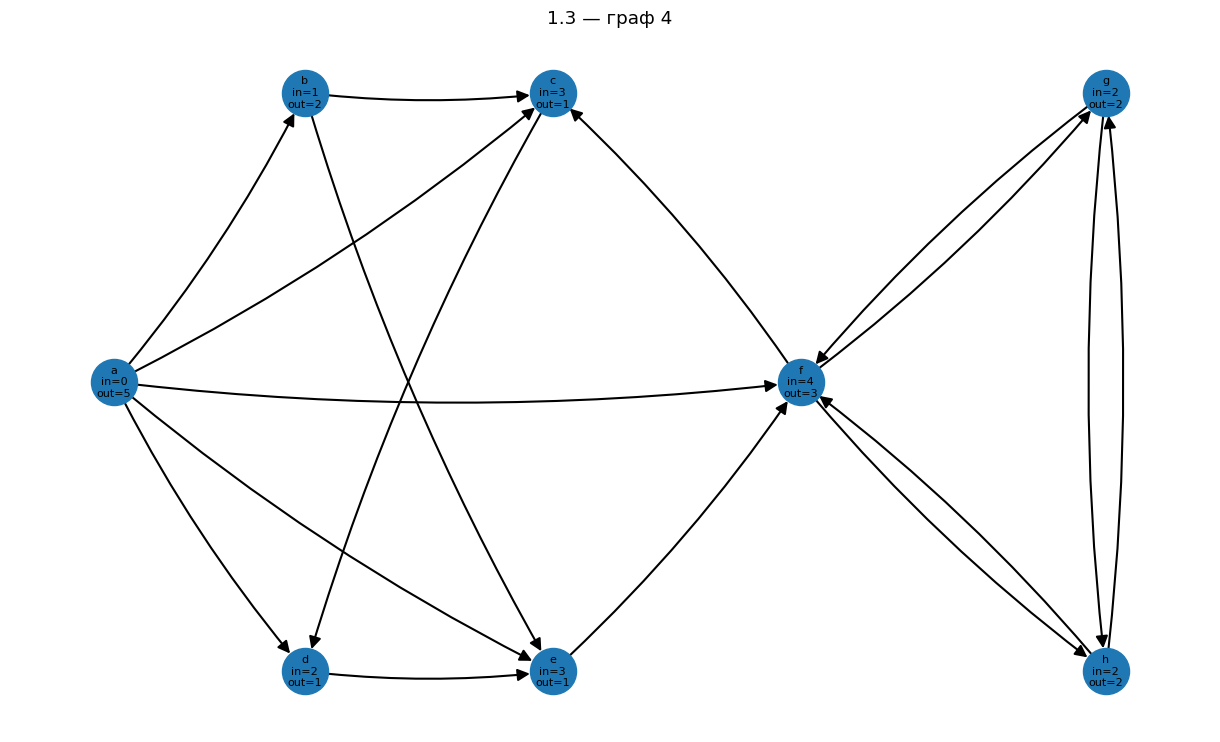

In [42]:
# Граф 1
G13_1 = nx.MultiGraph()
G13_1.add_nodes_from(["a", "b", "c", "d"])
G13_1.add_edges_from([
    ("a", "b"),
    ("b", "c"),
    ("b", "d"),
    ("a", "c"),
    ("c", "d"),
    ("c", "d"),
    ("a", "a"),
])

print("Граф 1")
print("Порядок:", G13_1.number_of_nodes())
print("Размер:", G13_1.number_of_edges())
print("Степени:", dict(G13_1.degree()))

pos = {"a": (0, 1.2), "b": (-1, 0), "c": (1, 0), "d": (0, -1.2)}
plt.figure(figsize=(8, 7))
nx.draw_networkx_nodes(G13_1, pos, node_size=900)
nx.draw_networkx_labels(
    G13_1,
    pos,
    labels={v: f"{v}\ndeg={G13_1.degree(v)}" for v in G13_1.nodes()},
    font_size=11
)
nx.draw_networkx_edges(
    G13_1,
    pos,
    edgelist=[("a", "b"), ("b", "c"), ("b", "d"), ("a", "c")],
    width=1.8
)
nx.draw_networkx_edges(
    G13_1,
    pos,
    edgelist=[("c", "d")],
    connectionstyle="arc3,rad=0.20",
    width=1.8
)
nx.draw_networkx_edges(
    G13_1,
    pos,
    edgelist=[("c", "d")],
    connectionstyle="arc3,rad=-0.20",
    width=1.8
)
nx.draw_networkx_edges(
    G13_1,
    pos,
    edgelist=[("a", "a")],
    connectionstyle="arc3,rad=0.8",
    width=1.8
)
plt.title("1.3 — граф 1")
plt.axis("off")
plt.show()


# Граф 2
G13_2 = nx.Graph()
G13_2.add_nodes_from(["A", "B", "C", "D", "E", "F", "G"])
G13_2.add_edges_from([
    ("B", "C"),
    ("C", "D"),
    ("B", "A"),
    ("F", "G"),
])

print("\nГраф 2")
print("Порядок:", G13_2.number_of_nodes())
print("Размер:", G13_2.number_of_edges())
print("Степени:", dict(G13_2.degree()))

pos = {
    "A": (0, -1.2),
    "B": (-1.5, 0),
    "C": (-0.7, 1.2),
    "D": (0.4, 1.45),
    "E": (0.45, 0),
    "F": (0.8, -1.0),
    "G": (1.35, 1.5),
}
draw_simple(
    G13_2,
    "1.3 — граф 2",
    pos=pos,
    labels={v: f"{v}\ndeg={G13_2.degree(v)}" for v in G13_2.nodes()}
)


# Граф 3
G13_3 = nx.MultiGraph()
G13_3.add_nodes_from([2, 3, 4, 5, 6])
G13_3.add_edges_from([
    (6, 2),
    (6, 3),
    (6, 4),
    (2, 4),
    (2, 2),
    (3, 3),
    (4, 4),
    (5, 5),
    (6, 6),
])

print("\nГраф 3")
print("Порядок:", G13_3.number_of_nodes())
print("Размер:", G13_3.number_of_edges())
print("Степени:", dict(G13_3.degree()))

pos = {6: (-1.5, 0), 2: (0, 1), 3: (1.5, 0), 4: (0.6, -1.2), 5: (-0.7, -1.5)}

plt.figure(figsize=(9, 7))
nx.draw_networkx_nodes(G13_3, pos, node_size=900)
nx.draw_networkx_labels(
    G13_3,
    pos,
    labels={v: f"{v}\ndeg={G13_3.degree(v)}" for v in G13_3.nodes()},
    font_size=11
)
nx.draw_networkx_edges(
    G13_3,
    pos,
    edgelist=[(6, 2), (6, 3), (6, 4), (2, 4)],
    width=1.8
)
for v in G13_3.nodes():
    nx.draw_networkx_edges(
        G13_3,
        pos,
        edgelist=[(v, v)],
        connectionstyle="arc3,rad=0.8",
        width=1.8
    )
plt.title("1.3 — граф 3")
plt.axis("off")
plt.show()


# Граф 4
G13_4 = nx.DiGraph()
G13_4.add_nodes_from(list("abcdefgh"))
G13_4.add_edges_from([
    ("a", "b"),
    ("a", "c"),
    ("a", "d"),
    ("a", "e"),
    ("a", "f"),
    ("b", "c"),
    ("b", "e"),
    ("c", "d"),
    ("d", "e"),
    ("e", "f"),
    ("f", "c"),
    ("f", "g"),
    ("g", "f"),
    ("f", "h"),
    ("h", "f"),
    ("g", "h"),
    ("h", "g"),
])

print("\nГраф 4")
print("Порядок:", G13_4.number_of_nodes())
print("Размер:", G13_4.number_of_edges())
for v in G13_4.nodes():
    print(
        f"{v}: in={G13_4.in_degree(v)}, "
        f"out={G13_4.out_degree(v)}, "
        f"degree={G13_4.degree(v)}"
    )

pos = {
    "a": (-3, 0),
    "b": (-2, 1.4),
    "c": (-0.7, 1.4),
    "d": (-2, -1.4),
    "e": (-0.7, -1.4),
    "f": (0.6, 0),
    "g": (2.2, 1.4),
    "h": (2.2, -1.4),
}

plt.figure(figsize=(12, 7))
nx.draw(
    G13_4,
    pos,
    with_labels=False,
    node_size=1100,
    arrows=True,
    arrowsize=18,
    width=1.5,
    connectionstyle="arc3,rad=0.06"
)
nx.draw_networkx_labels(
    G13_4,
    pos,
    labels={
        v: f"{v}\nin={G13_4.in_degree(v)}\nout={G13_4.out_degree(v)}"
        for v in G13_4.nodes()
    },
    font_size=8
)
plt.title("1.3 — граф 4")
plt.axis("off")
plt.show()

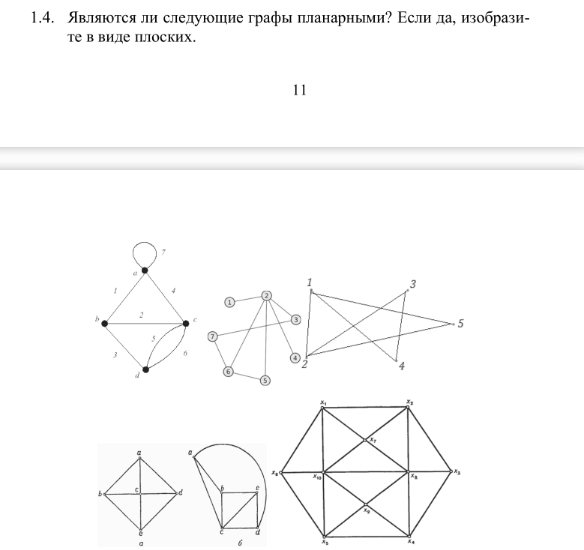

Граф 1: планарный = True


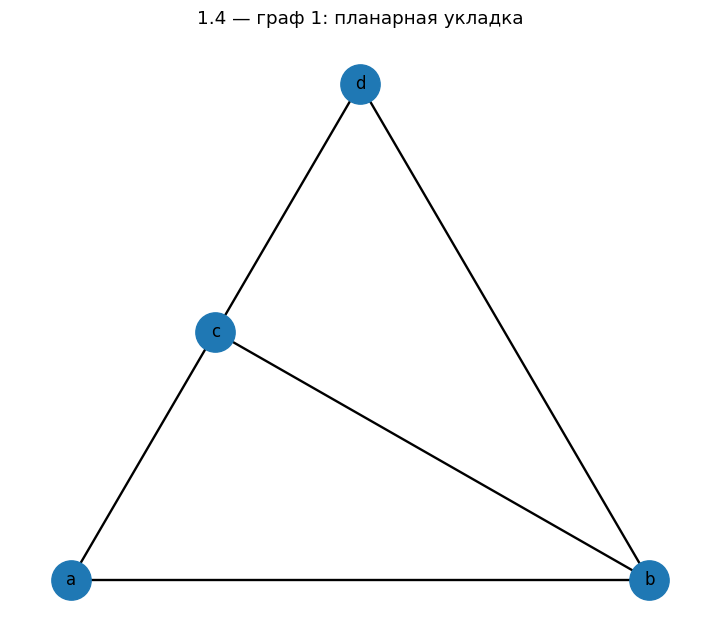

Граф 2: планарный = True


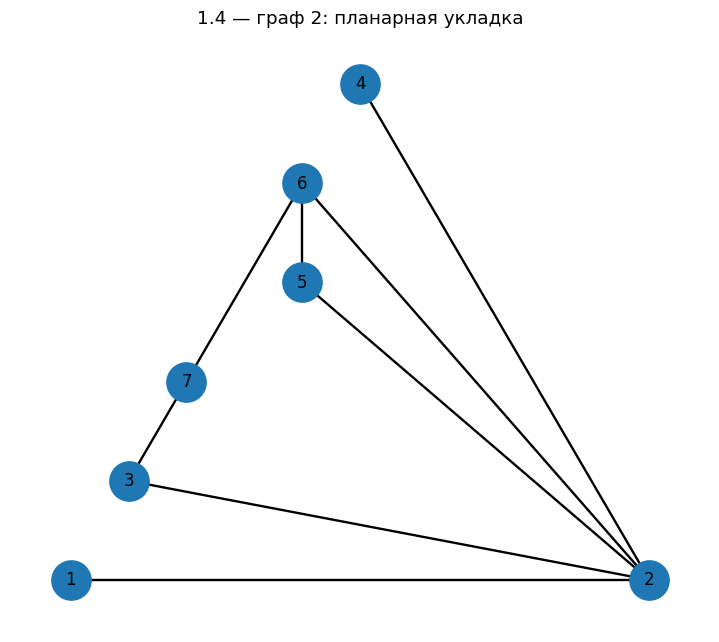

Граф 3: планарный = True


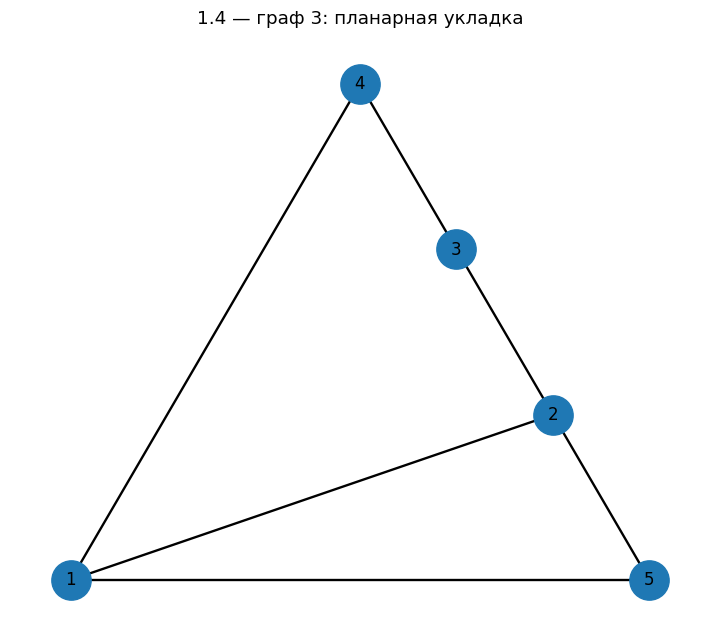

Граф 4: планарный = True


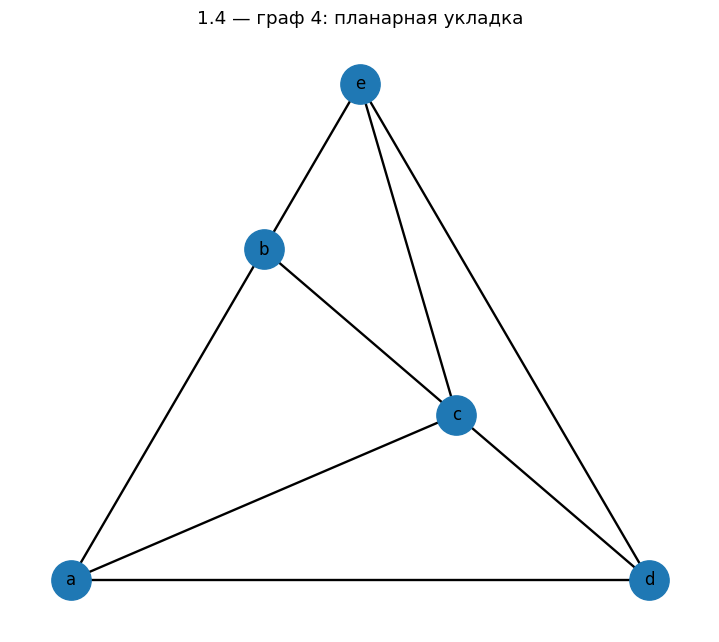

Граф 5: планарный = True


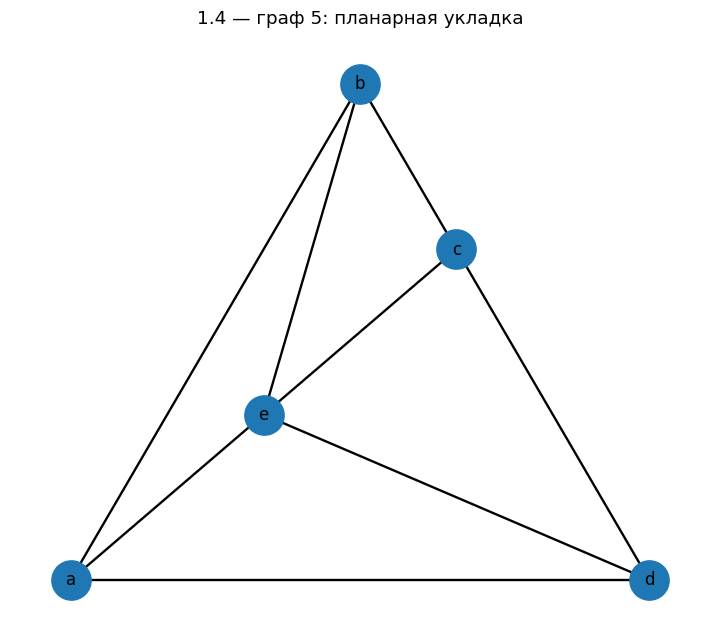

Граф 6: планарный = True


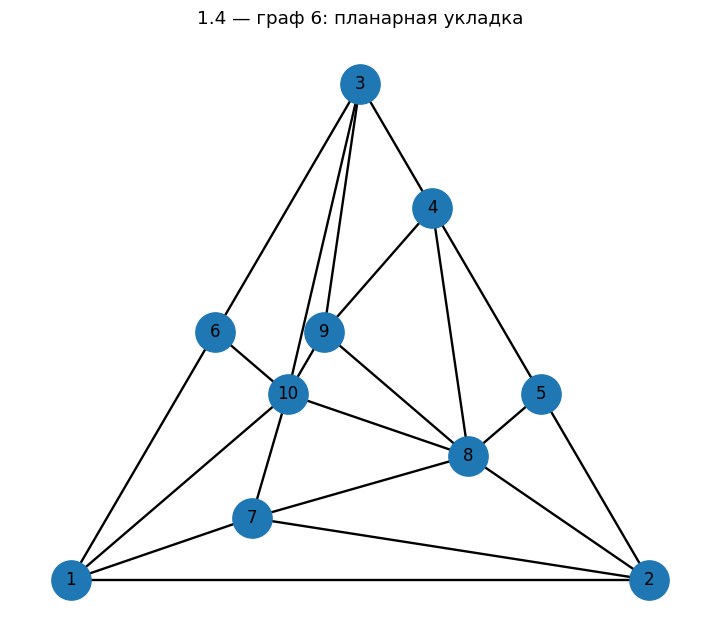

In [43]:
G14_1 = nx.MultiGraph()
G14_1.add_nodes_from(["a", "b", "c", "d"])
G14_1.add_edges_from([
    ("a", "b"),
    ("b", "c"),
    ("b", "d"),
    ("a", "c"),
    ("c", "d"),
    ("c", "d"),
    ("a", "a"),
])

G14_2 = nx.Graph()
G14_2.add_nodes_from(range(1, 8))
G14_2.add_edges_from([
    (1, 2),
    (2, 3),
    (2, 4),
    (2, 5),
    (2, 6),
    (3, 7),
    (7, 6),
    (6, 5),
])

G14_3 = nx.Graph()
G14_3.add_nodes_from(range(1, 6))
G14_3.add_edges_from([
    (1, 2),
    (1, 4),
    (1, 5),
    (2, 3),
    (2, 5),
    (3, 4),
])

G14_4 = nx.Graph()
G14_4.add_nodes_from(["a", "b", "c", "d", "e"])
G14_4.add_edges_from([
    ("a", "b"),
    ("b", "e"),
    ("e", "d"),
    ("d", "a"),
    ("c", "a"),
    ("c", "b"),
    ("c", "d"),
    ("c", "e"),
])

G14_5 = nx.Graph()
G14_5.add_nodes_from(["a", "b", "c", "d", "e"])
G14_5.add_edges_from([
    ("a", "b"),
    ("a", "e"),
    ("a", "d"),
    ("b", "c"),
    ("c", "d"),
    ("d", "e"),
    ("e", "b"),
    ("e", "c"),
])

G14_6 = nx.Graph()
G14_6.add_nodes_from(range(1, 11))
G14_6.add_edges_from([
    (6, 1), (1, 2), (2, 5), (5, 4), (4, 3), (3, 6),
    (1, 10), (10, 3),
    (2, 8), (8, 4),
    (6, 10), (10, 8), (8, 5),
    (1, 7), (7, 8), (10, 7), (7, 2),
    (10, 9), (9, 4), (3, 9), (9, 8),
])

graphs_14 = [G14_1, G14_2, G14_3, G14_4, G14_5, G14_6]

for i, G in enumerate(graphs_14, start=1):
    H = simple_projection(G) if G.is_multigraph() else G.copy()
    planar, embedding = nx.check_planarity(H)
    print(f"Граф {i}: планарный = {planar}")

    if planar:
        pos = nx.planar_layout(H)
        plt.figure(figsize=(7, 6))
        nx.draw(H, pos, with_labels=True, node_size=800, width=1.7)
        plt.title(f"1.4 — граф {i}: планарная укладка")
        plt.axis("off")
        plt.show()

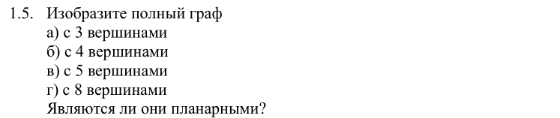

K_3: |V|=3, |E|=3, планарный=True


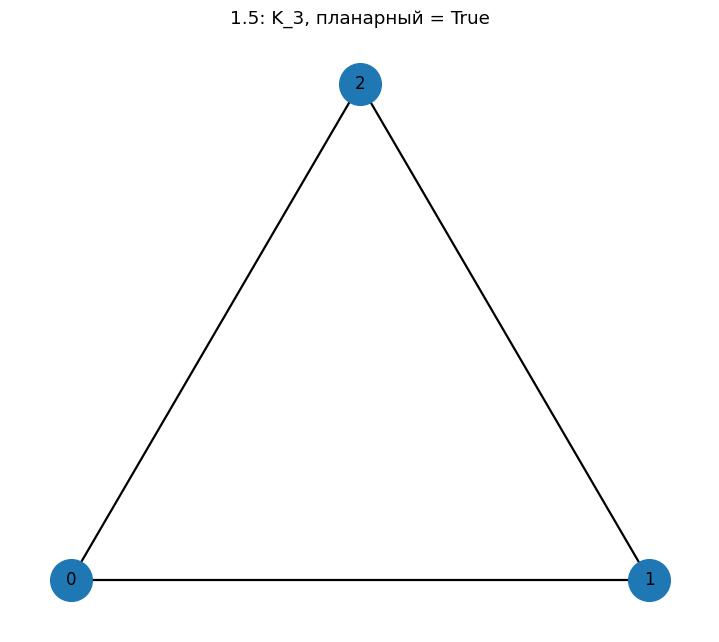

K_4: |V|=4, |E|=6, планарный=True


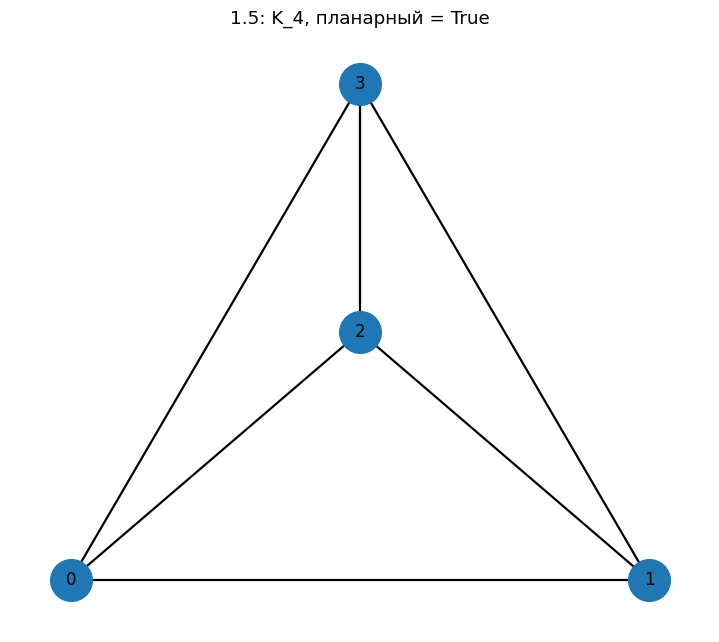

K_5: |V|=5, |E|=10, планарный=False


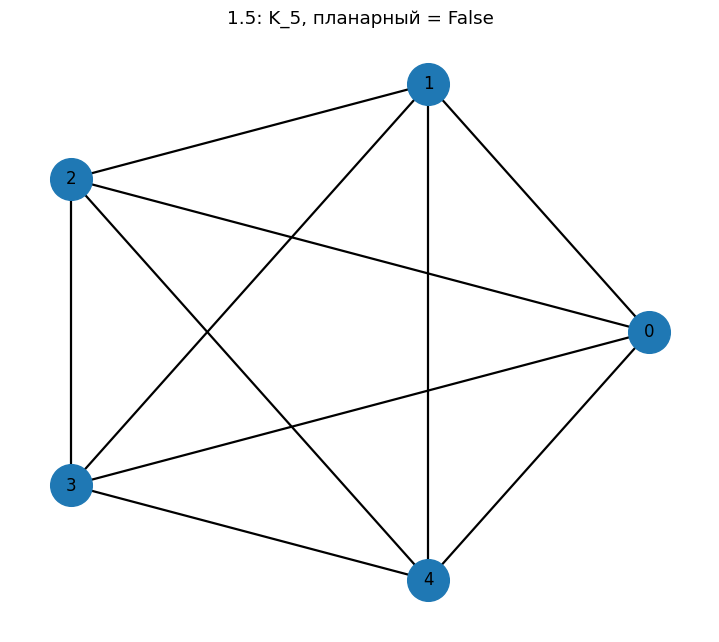

K_8: |V|=8, |E|=28, планарный=False


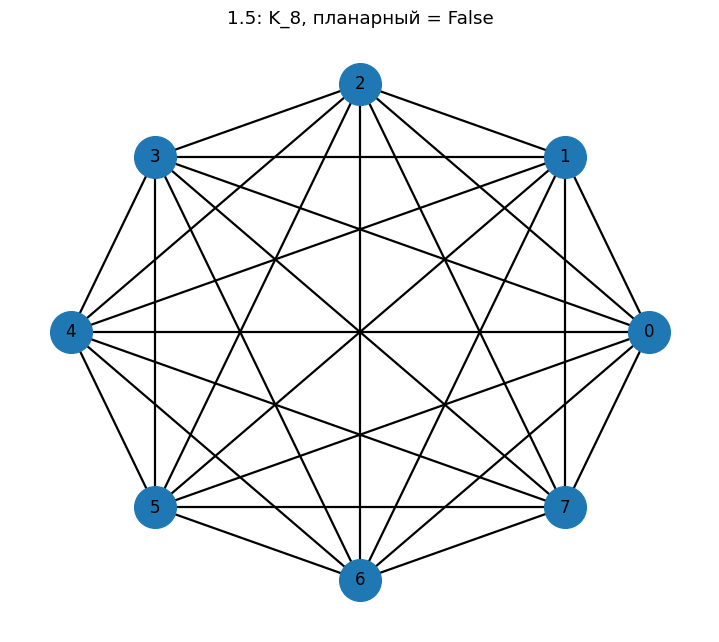

Ответ: K3 и K4 планарны; K5 и K8 непланарны.


In [44]:
for n in [3, 4, 5, 8]:
    G = nx.complete_graph(n)
    planar, _ = nx.check_planarity(G)

    print(f"K_{n}: |V|={G.number_of_nodes()}, |E|={G.number_of_edges()}, планарный={planar}")

    if planar:
        pos = nx.planar_layout(G)
    else:
        pos = nx.circular_layout(G)

    plt.figure(figsize=(7, 6))
    nx.draw(G, pos, with_labels=True, node_size=900, width=1.6)
    plt.title(f"1.5: K_{n}, планарный = {planar}")
    plt.axis("off")
    plt.show()

print("Ответ: K3 и K4 планарны; K5 и K8 непланарны.")

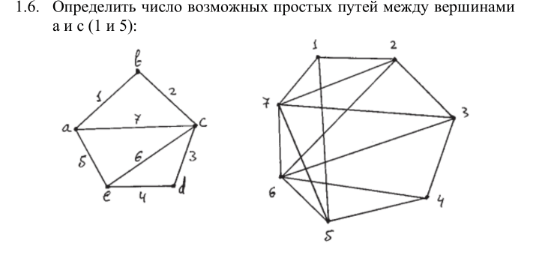

Первый граф
Число простых путей между a и c: 4
1 a->b->c
2 a->e->d->c
3 a->e->c
4 a->c


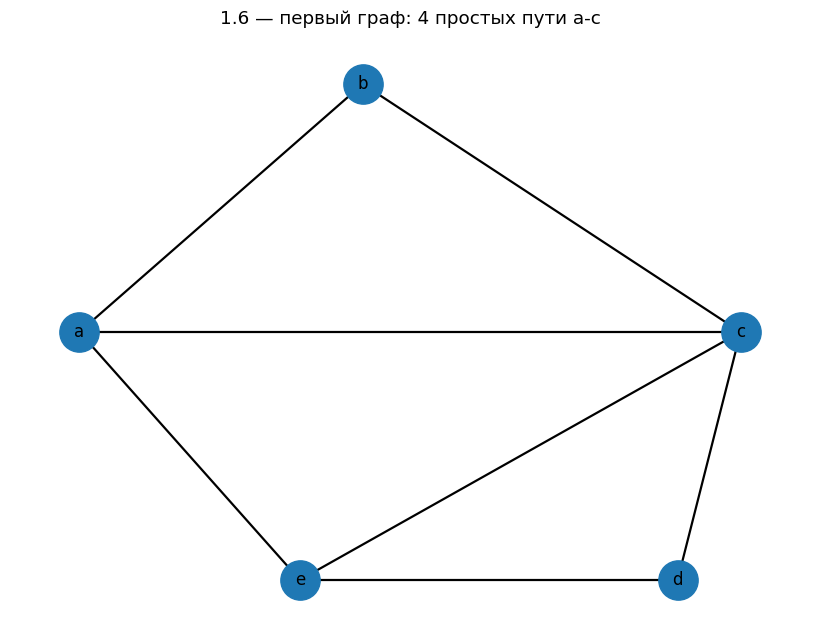


Второй граф
Число простых путей между 1 и 5: 43
1 1->2->3->4->5
2 1->2->3->4->6->5
3 1->2->3->4->6->7->5
4 1->2->3->7->6->5
5 1->2->3->7->6->4->5
6 1->2->3->7->5
7 1->2->3->6->5
8 1->2->3->6->7->5
9 1->2->3->6->4->5
10 1->2->7->6->5
11 1->2->7->6->3->4->5
12 1->2->7->6->4->5
13 1->2->7->3->4->5
14 1->2->7->3->4->6->5
15 1->2->7->3->6->5
16 1->2->7->3->6->4->5
17 1->2->7->5
18 1->2->6->5
19 1->2->6->7->3->4->5
20 1->2->6->7->5
21 1->2->6->3->4->5
22 1->2->6->3->7->5
23 1->2->6->4->3->7->5
24 1->2->6->4->5
25 1->7->6->5
26 1->7->6->2->3->4->5
27 1->7->6->3->4->5
28 1->7->6->4->5
29 1->7->2->3->4->5
30 1->7->2->3->4->6->5
31 1->7->2->3->6->5
32 1->7->2->3->6->4->5
33 1->7->2->6->5
34 1->7->2->6->3->4->5
35 1->7->2->6->4->5
36 1->7->3->2->6->5
37 1->7->3->2->6->4->5
38 1->7->3->4->5
39 1->7->3->4->6->5
40 1->7->3->6->5
41 1->7->3->6->4->5
42 1->7->5
43 1->5


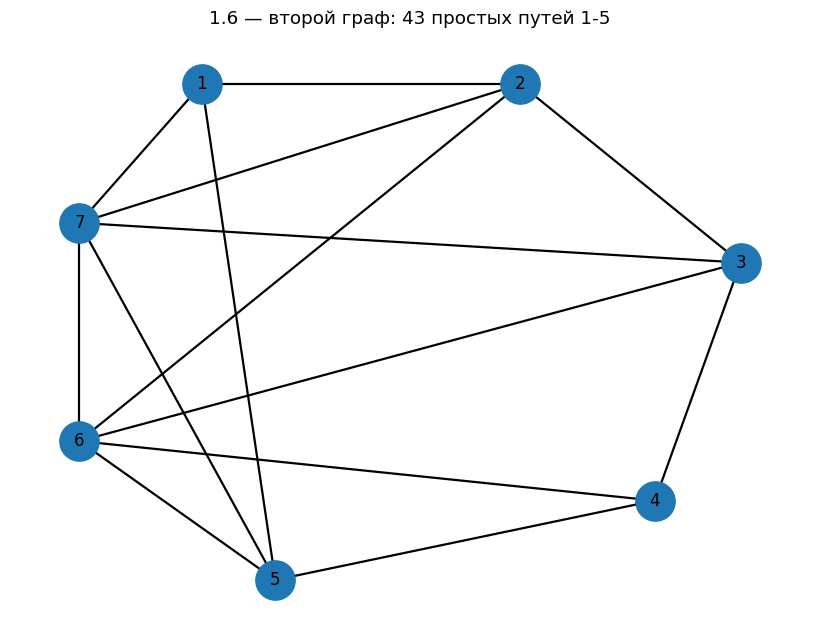

In [45]:
# Первый граф: пути между a и c
G16_1 = nx.Graph()
G16_1.add_edges_from([
    ("a", "b"),
    ("b", "c"),
    ("c", "d"),
    ("d", "e"),
    ("e", "a"),
    ("e", "c"),
    ("a", "c"),
])

paths_ac = list(nx.all_simple_paths(G16_1, source="a", target="c"))

print("Первый граф")
print("Число простых путей между a и c:", len(paths_ac))
for i, path in enumerate(paths_ac, start=1):
    print(i, "->".join(path))

pos1 = {
    "a": (-1.4, 0),
    "b": (-0.5, 1.2),
    "c": (0.7, 0),
    "d": (0.5, -1.2),
    "e": (-0.7, -1.2),
}
draw_simple(G16_1, f"1.6 — первый граф: {len(paths_ac)} простых пути a-c", pos=pos1)


# Второй граф: пути между 1 и 5
G16_2 = nx.Graph()
G16_2.add_edges_from([
    (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1),
    (1, 5),
    (7, 2), (7, 3), (7, 5),
    (6, 2), (6, 3), (6, 4),
])

paths_15 = list(nx.all_simple_paths(G16_2, source=1, target=5))

print("\nВторой граф")
print("Число простых путей между 1 и 5:", len(paths_15))
for i, path in enumerate(paths_15, start=1):
    print(i, "->".join(map(str, path)))

pos2 = {
    1: (-0.7, 1.1),
    2: (0.6, 1.1),
    3: (1.5, 0.2),
    4: (1.15, -1.0),
    5: (-0.4, -1.4),
    6: (-1.2, -0.7),
    7: (-1.2, 0.4),
}
draw_simple(G16_2, f"1.6 — второй граф: {len(paths_15)} простых путей 1-5", pos=pos2)

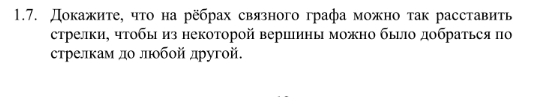

Выбираем произвольную вершину r.
Строим остовное дерево BFS.
Все рёбра дерева ориентируем от корня к потомкам.
Остальные рёбра можно ориентировать произвольно.
Достижимость из r: {'r': True, 'a': True, 'b': True, 'c': True, 'd': True, 'e': True}
Следовательно, из r можно добраться по стрелкам до любой вершины.


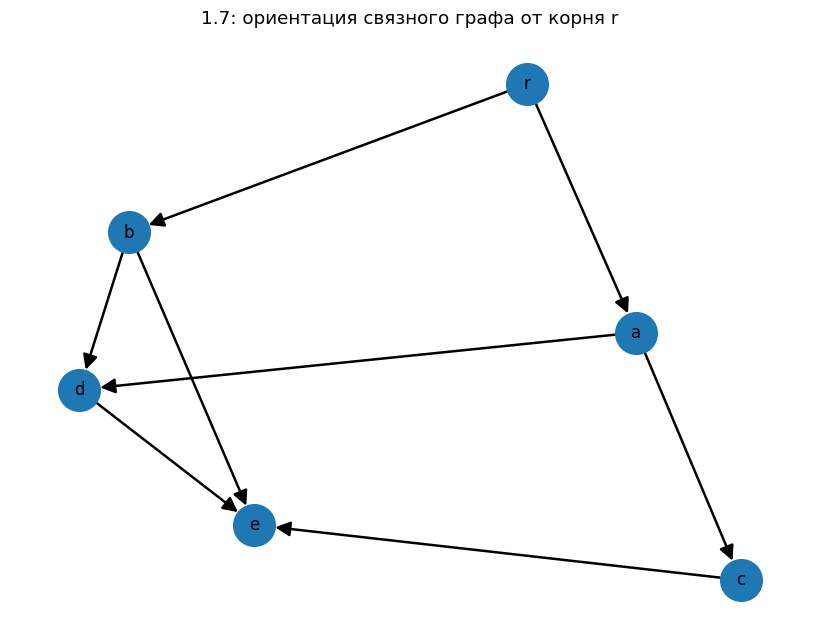

In [46]:
G17 = nx.Graph()
G17.add_edges_from([
    ("r", "a"), ("r", "b"),
    ("a", "c"), ("a", "d"),
    ("b", "d"), ("b", "e"),
    ("c", "e"), ("d", "e"),
])

root = "r"

T = nx.bfs_tree(G17, root)
D17 = nx.DiGraph()
D17.add_nodes_from(G17.nodes())

tree_edges = set(T.edges())

for u, v in tree_edges:
    D17.add_edge(u, v)

for u, v in G17.edges():
    if (u, v) not in tree_edges and (v, u) not in tree_edges:
        if str(u) < str(v):
            D17.add_edge(u, v)
        else:
            D17.add_edge(v, u)

reachable = {v: nx.has_path(D17, root, v) for v in D17.nodes()}

print("Выбираем произвольную вершину r.")
print("Строим остовное дерево BFS.")
print("Все рёбра дерева ориентируем от корня к потомкам.")
print("Остальные рёбра можно ориентировать произвольно.")
print("Достижимость из r:", reachable)
print("Следовательно, из r можно добраться по стрелкам до любой вершины.")

pos = nx.spring_layout(G17, seed=4)
plt.figure(figsize=(8, 6))
nx.draw(
    D17,
    pos,
    with_labels=True,
    node_size=900,
    arrows=True,
    arrowsize=22,
    width=1.8
)
plt.title("1.7: ориентация связного графа от корня r")
plt.axis("off")
plt.show()

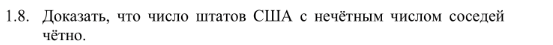

Лемма о рукопожатиях:
Сумма степеней = 24
2|E| = 24
Вершины нечётной степени в иллюстративном графе: ['S2', 'S3', 'S5', 'S6', 'S7', 'S10']
Их количество: 6
Число вершин нечётной степени всегда чётно.
Значит, число штатов США с нечётным числом соседей также чётно.


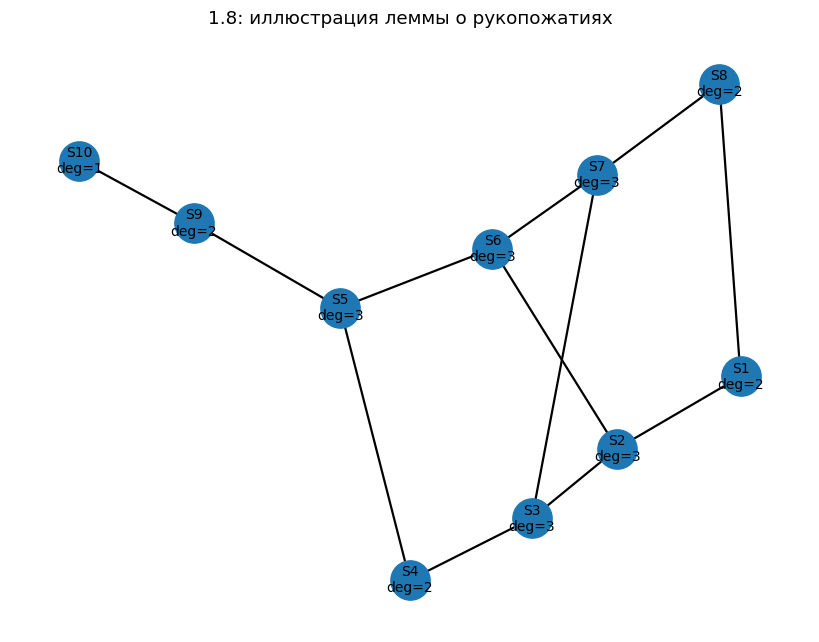

In [47]:
G18 = nx.Graph()
G18.add_nodes_from([f"S{i}" for i in range(1, 11)])
G18.add_edges_from([
    ("S1", "S2"), ("S2", "S3"), ("S3", "S4"), ("S4", "S5"),
    ("S5", "S6"), ("S6", "S7"), ("S7", "S8"), ("S8", "S1"),
    ("S2", "S6"), ("S3", "S7"), ("S5", "S9"), ("S9", "S10"),
])

odd_vertices = [v for v, d in G18.degree() if d % 2 == 1]
sum_degrees = sum(dict(G18.degree()).values())

print("Лемма о рукопожатиях:")
print("Сумма степеней =", sum_degrees)
print("2|E| =", 2 * G18.number_of_edges())
print("Вершины нечётной степени в иллюстративном графе:", odd_vertices)
print("Их количество:", len(odd_vertices))
print("Число вершин нечётной степени всегда чётно.")
print("Значит, число штатов США с нечётным числом соседей также чётно.")

labels = {v: f"{v}\ndeg={G18.degree(v)}" for v in G18.nodes()}
draw_simple(
    G18,
    "1.8: иллюстрация леммы о рукопожатиях",
    pos=nx.spring_layout(G18, seed=8),
    labels=labels
)

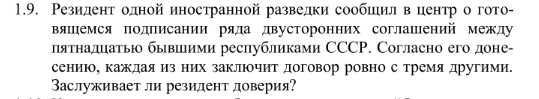

In [48]:
degree_sequence_19 = [3] * 15

print("Требуемая последовательность степеней:", degree_sequence_19)
print("Сумма степеней:", sum(degree_sequence_19))
print("NetworkX: последовательность графична =", nx.is_graphical(degree_sequence_19))
print("15 * 3 = 45 — нечётное число.")
print("Но сумма степеней любого неориентированного графа равна 2|E| и поэтому чётна.")
print("Ответ: резидент не прав.")

Требуемая последовательность степеней: [3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
Сумма степеней: 45
NetworkX: последовательность графична = False
15 * 3 = 45 — нечётное число.
Но сумма степеней любого неориентированного графа равна 2|E| и поэтому чётна.
Ответ: резидент не прав.


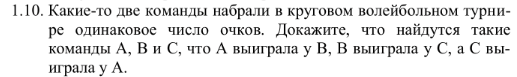

Пример минимального цикла:
A выиграла у B, B выиграла у C, C выиграла у A.
Число побед: {'A': 1, 'B': 1, 'C': 1}

Доказательство:
Если в турнире нет ориентированного цикла, турнир транзитивен.
Тогда команды можно упорядочить так, что их числа побед равны 0, 1, ..., n-1,
то есть все числа побед различны.
Следовательно, если две команды набрали одинаковое число очков,
ориентированный цикл существует.
В турнире кратчайший ориентированный цикл обязательно имеет длину 3,
поэтому существуют A, B, C: A->B, B->C, C->A.


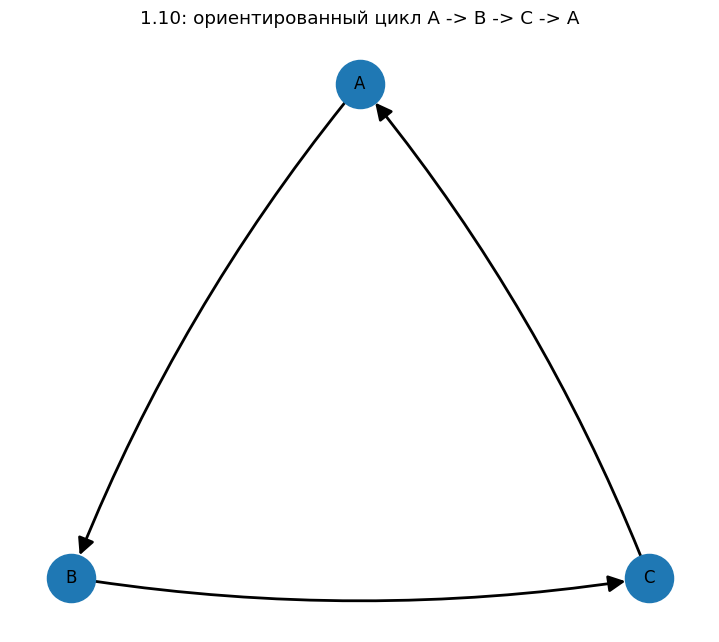

In [49]:
G110 = nx.DiGraph()
G110.add_edges_from([
    ("A", "B"),
    ("B", "C"),
    ("C", "A"),
])

scores = {v: G110.out_degree(v) for v in G110.nodes()}

print("Пример минимального цикла:")
print("A выиграла у B, B выиграла у C, C выиграла у A.")
print("Число побед:", scores)
print()
print("Доказательство:")
print("Если в турнире нет ориентированного цикла, турнир транзитивен.")
print("Тогда команды можно упорядочить так, что их числа побед равны 0, 1, ..., n-1,")
print("то есть все числа побед различны.")
print("Следовательно, если две команды набрали одинаковое число очков,")
print("ориентированный цикл существует.")
print("В турнире кратчайший ориентированный цикл обязательно имеет длину 3,")
print("поэтому существуют A, B, C: A->B, B->C, C->A.")

pos = {"A": (0, 1), "B": (-1, -0.7), "C": (1, -0.7)}

plt.figure(figsize=(7, 6))
nx.draw(
    G110,
    pos,
    with_labels=True,
    node_size=1200,
    arrows=True,
    arrowsize=25,
    width=2.0,
    connectionstyle="arc3,rad=0.08"
)
plt.title("1.10: ориентированный цикл A -> B -> C -> A")
plt.axis("off")
plt.show()

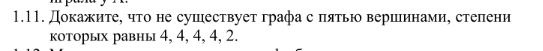

Последовательность: [4, 4, 4, 4, 2]
NetworkX: графична = False

Если четыре вершины имеют степень 4 в графе на 5 вершинах,
каждая из них соединена со всеми остальными вершинами.
Значит, пятая вершина обязана быть соединена со всеми четырьмя
и тоже иметь степень 4, а не 2.
Ответ: такого графа не существует.


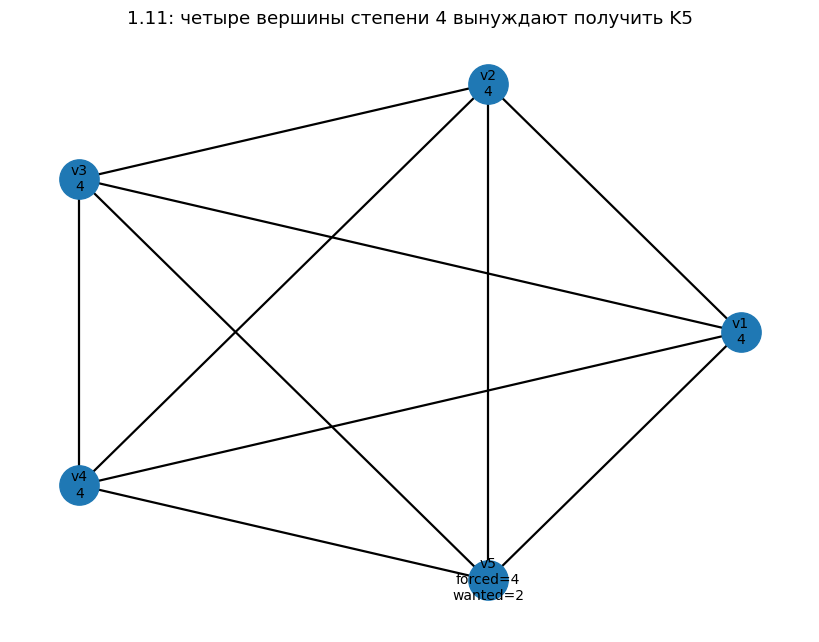

In [50]:
degree_sequence_111 = [4, 4, 4, 4, 2]

print("Последовательность:", degree_sequence_111)
print("NetworkX: графична =", nx.is_graphical(degree_sequence_111))
print()
print("Если четыре вершины имеют степень 4 в графе на 5 вершинах,")
print("каждая из них соединена со всеми остальными вершинами.")
print("Значит, пятая вершина обязана быть соединена со всеми четырьмя")
print("и тоже иметь степень 4, а не 2.")
print("Ответ: такого графа не существует.")

G111_forced = nx.complete_graph(["v1", "v2", "v3", "v4", "v5"])

labels = {
    "v1": "v1\n4",
    "v2": "v2\n4",
    "v3": "v3\n4",
    "v4": "v4\n4",
    "v5": "v5\nforced=4\nwanted=2",
}

draw_simple(
    G111_forced,
    "1.11: четыре вершины степени 4 вынуждают получить K5",
    pos=nx.circular_layout(G111_forced),
    labels=labels
)

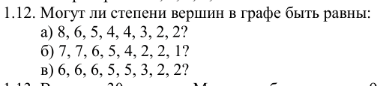

a) [8, 6, 5, 4, 4, 3, 2, 2]
   сумма степеней = 34
   графична = False
   причина: при 8 вершинах максимальная степень равна 7, но указана степень 8.



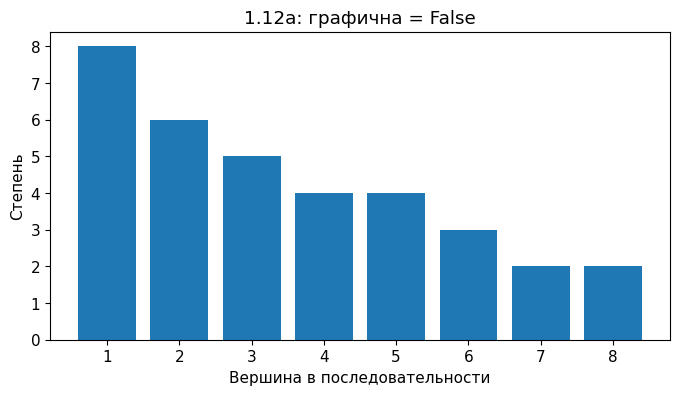

б) [7, 7, 6, 5, 4, 2, 2, 1]
   сумма степеней = 34
   графична = False
   причина: последовательность не проходит критерий Эрдёша—Галлаи.



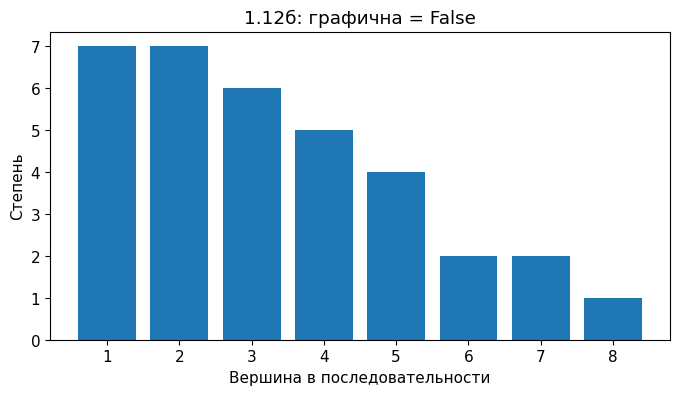

в) [6, 6, 6, 5, 5, 3, 2, 2]
   сумма степеней = 35
   графична = False
   причина: сумма степеней нечётна.



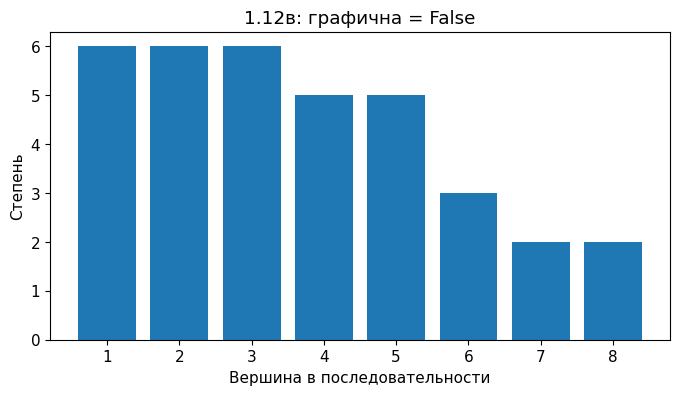

In [51]:
sequences_112 = {
    "a": [8, 6, 5, 4, 4, 3, 2, 2],
    "б": [7, 7, 6, 5, 4, 2, 2, 1],
    "в": [6, 6, 6, 5, 5, 3, 2, 2],
}

for name, seq in sequences_112.items():
    graphical = nx.is_graphical(seq, method="eg")
    print(f"{name}) {seq}")
    print("   сумма степеней =", sum(seq))
    print("   графична =", graphical)

    if name == "a":
        print("   причина: при 8 вершинах максимальная степень равна 7, но указана степень 8.")
    elif name == "б":
        print("   причина: последовательность не проходит критерий Эрдёша—Галлаи.")
    elif name == "в":
        print("   причина: сумма степеней нечётна.")
    print()

    plt.figure(figsize=(8, 4))
    plt.bar(range(1, len(seq) + 1), seq)
    plt.xticks(range(1, len(seq) + 1))
    plt.xlabel("Вершина в последовательности")
    plt.ylabel("Степень")
    plt.title(f"1.12{name}: графична = {graphical}")
    plt.show()

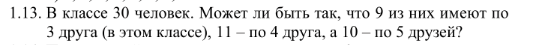

Всего человек: 30
9 человек имеют по 3 друга
11 человек имеют по 4 друга
10 человек имеют по 5 друзей
Сумма степеней: 121
NetworkX: последовательность графична = False
9*3 + 11*4 + 10*5 = 121
Сумма нечётна, а по лемме о рукопожатиях она должна быть чётной.
Ответ: нет, так быть не может.


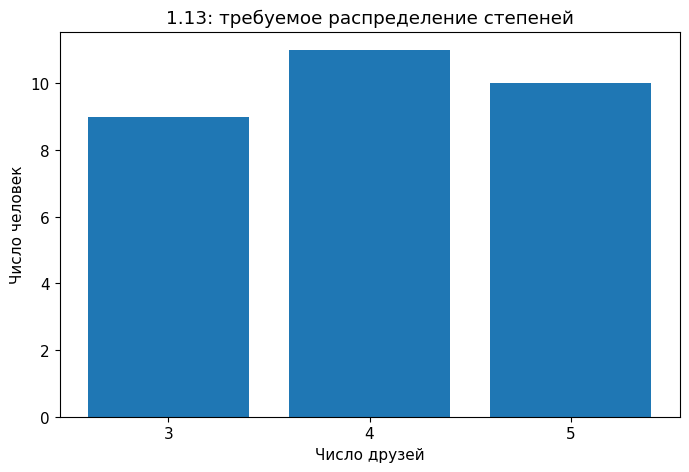

In [52]:
degrees_113 = [3] * 9 + [4] * 11 + [5] * 10

print("Всего человек:", len(degrees_113))
print("9 человек имеют по 3 друга")
print("11 человек имеют по 4 друга")
print("10 человек имеют по 5 друзей")
print("Сумма степеней:", sum(degrees_113))
print("NetworkX: последовательность графична =", nx.is_graphical(degrees_113))
print("9*3 + 11*4 + 10*5 =", 9*3 + 11*4 + 10*5)
print("Сумма нечётна, а по лемме о рукопожатиях она должна быть чётной.")
print("Ответ: нет, так быть не может.")

plt.figure(figsize=(8, 5))
plt.bar([3, 4, 5], [9, 11, 10])
plt.xticks([3, 4, 5])
plt.xlabel("Число друзей")
plt.ylabel("Число человек")
plt.title("1.13: требуемое распределение степеней")
plt.show()

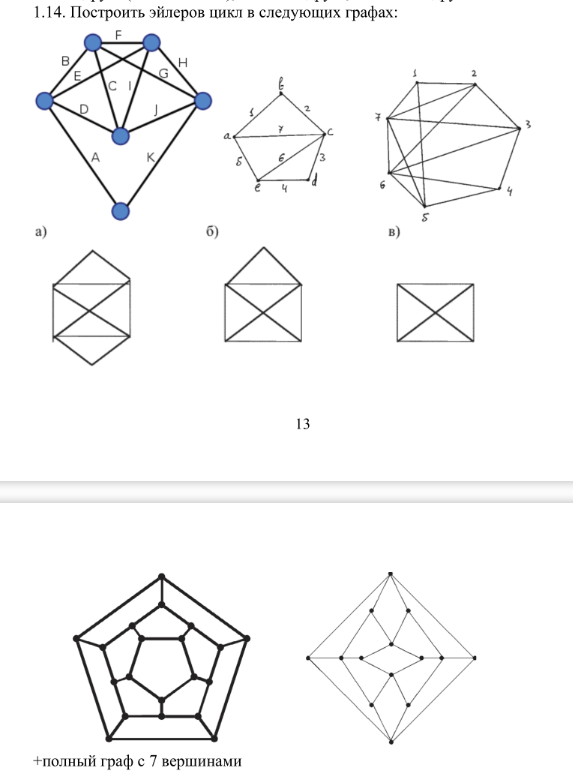


1.14a
|V| = 6 |E| = 11
Степени: {'L': 4, 'Btm': 2, 'TL': 4, 'C': 4, 'TR': 4, 'R': 4}
Эйлеров граф: True
Эйлеров цикл:
[('L', 'TR'), ('TR', 'R'), ('R', 'C'), ('C', 'TR'), ('TR', 'TL'), ('TL', 'C'), ('C', 'L'), ('L', 'TL'), ('TL', 'R'), ('R', 'Btm'), ('Btm', 'L')]


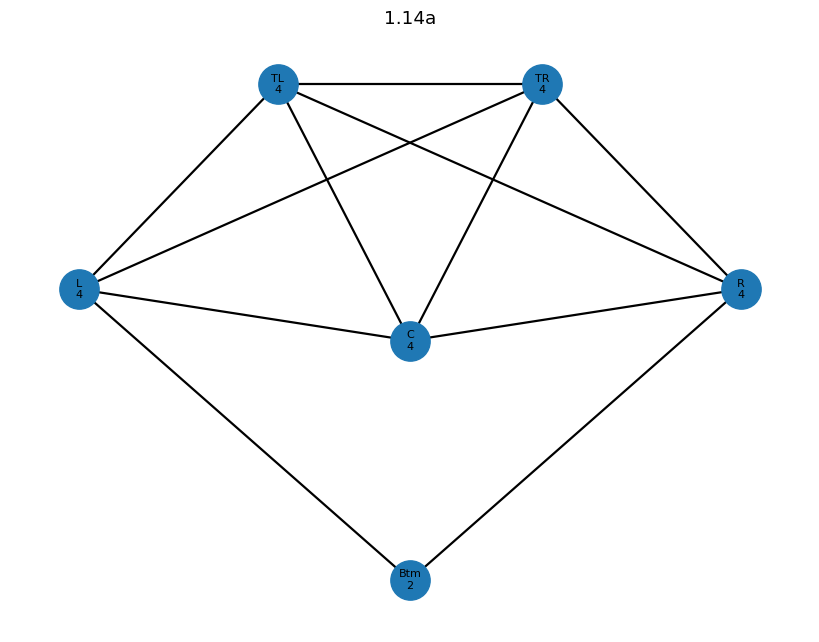


1.14б
|V| = 5 |E| = 7
Степени: {'a': 3, 'b': 2, 'c': 4, 'd': 2, 'e': 3}
Эйлеров граф: False
Эйлерова цикла нет, но есть эйлеров путь:
[('a', 'b'), ('b', 'c'), ('c', 'a'), ('a', 'e'), ('e', 'c'), ('c', 'd'), ('d', 'e')]


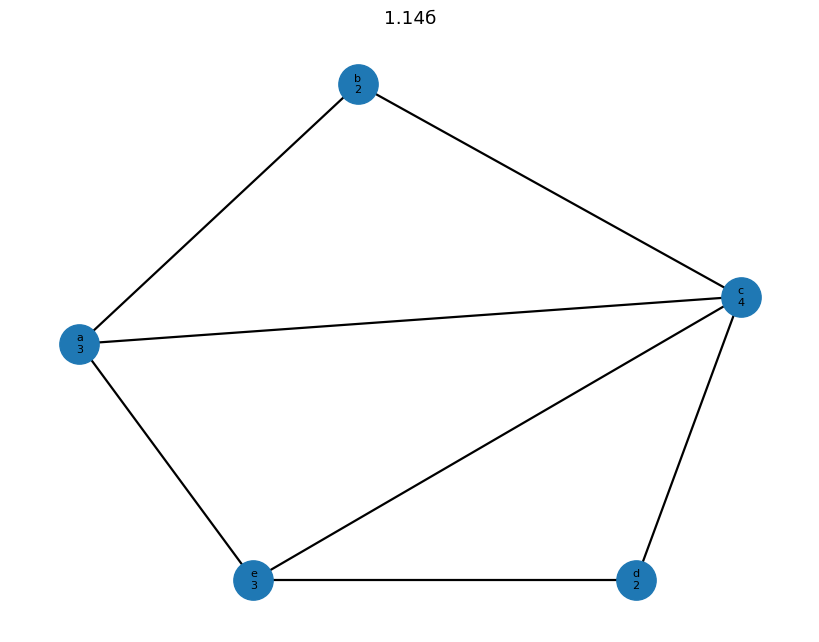


1.14в
|V| = 7 |E| = 14
Степени: {1: 3, 2: 4, 3: 4, 4: 3, 5: 4, 6: 5, 7: 5}
Эйлеров граф: False
Эйлерова цикла нет.
Вершины нечётной степени: [1, 4, 6, 7]


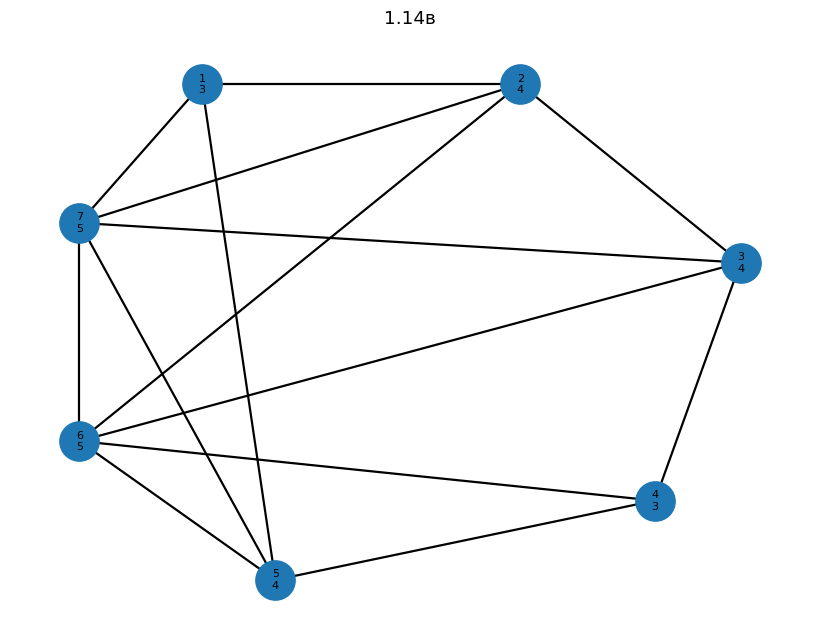


1.14 — малый граф 1
|V| = 6 |E| = 10
Степени: {'T': 2, 'UL': 4, 'UR': 4, 'LL': 4, 'B': 2, 'LR': 4}
Эйлеров граф: True
Эйлеров цикл:
[('T', 'UR'), ('UR', 'LR'), ('LR', 'B'), ('B', 'LL'), ('LL', 'LR'), ('LR', 'UL'), ('UL', 'UR'), ('UR', 'LL'), ('LL', 'UL'), ('UL', 'T')]


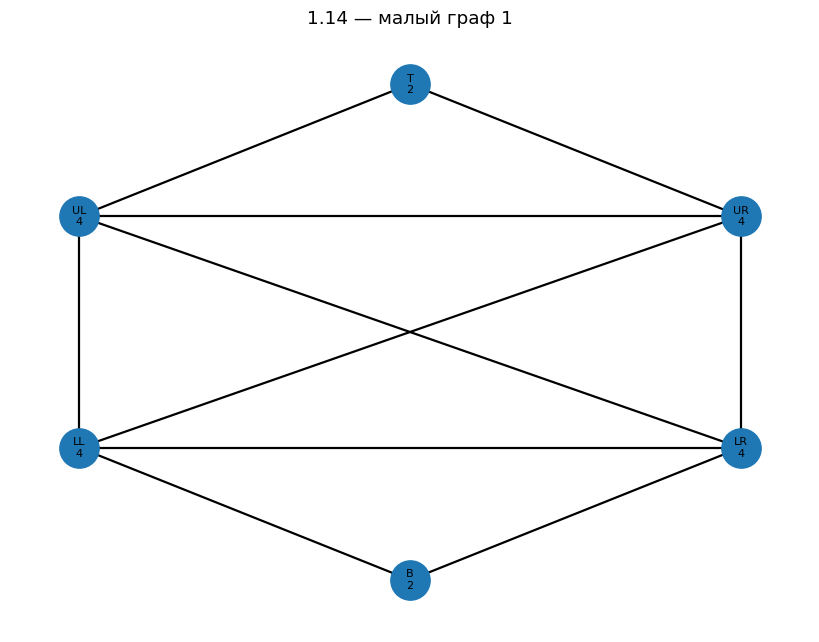


1.14 — малый граф 2
|V| = 5 |E| = 8
Степени: {'T': 2, 'UL': 4, 'UR': 4, 'LL': 3, 'LR': 3}
Эйлеров граф: False
Эйлерова цикла нет, но есть эйлеров путь:
[('LL', 'UL'), ('UL', 'T'), ('T', 'UR'), ('UR', 'UL'), ('UL', 'LR'), ('LR', 'UR'), ('UR', 'LL'), ('LL', 'LR')]


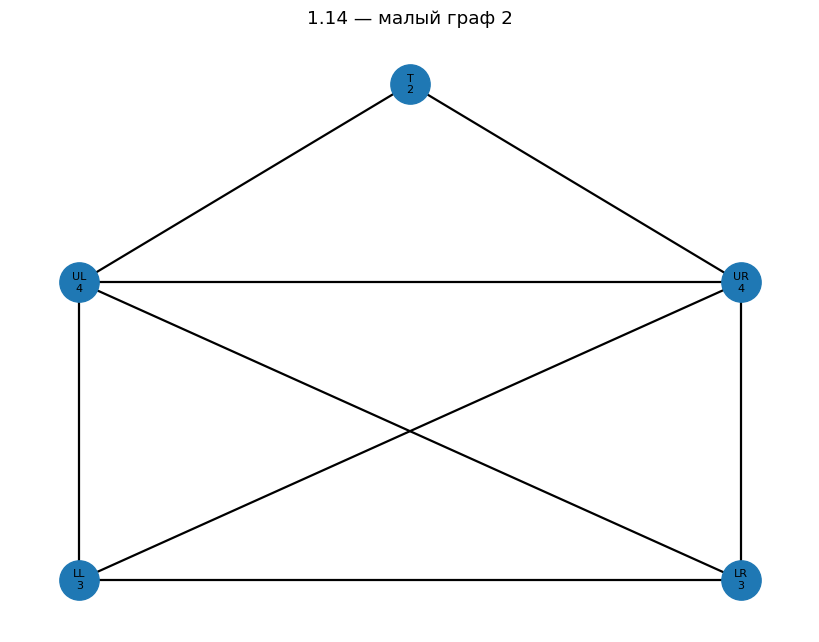


1.14 — малый граф 3 (K4)
|V| = 4 |E| = 6
Степени: {'UL': 3, 'UR': 3, 'LR': 3, 'LL': 3}
Эйлеров граф: False
Эйлерова цикла нет.
Вершины нечётной степени: ['UL', 'UR', 'LR', 'LL']


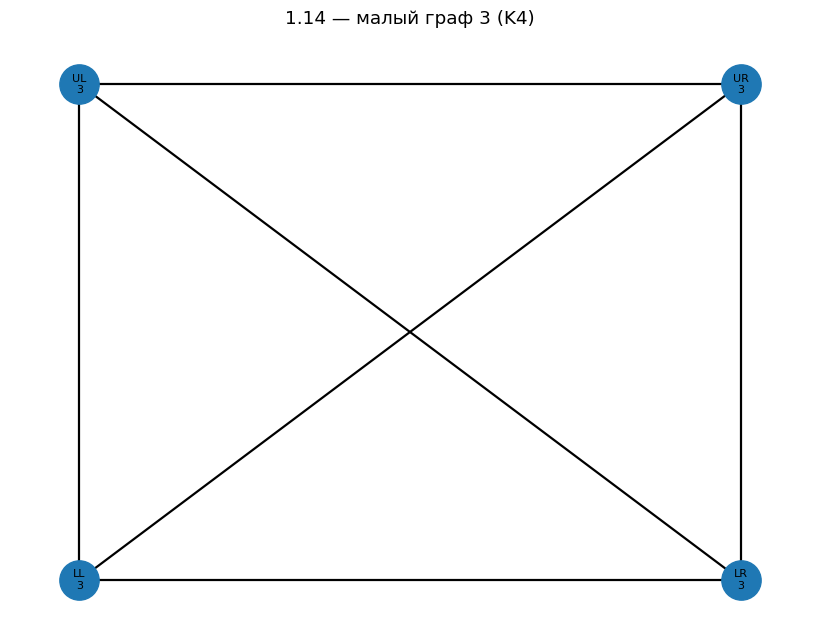


1.14 — додекаэдральный граф
|V| = 20 |E| = 30
Степени: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 3, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3, 16: 3, 17: 3, 18: 3, 19: 3}
Эйлеров граф: False
Эйлерова цикла нет.
Вершины нечётной степени: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


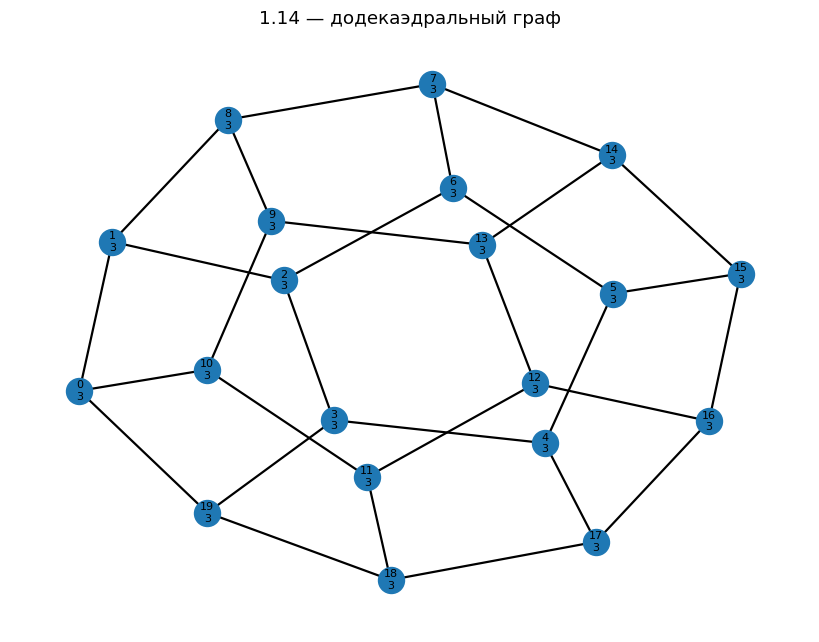


1.14 — четырёхмерный гиперкуб Q4
|V| = 16 |E| = 32
Степени: {0: 4, 1: 4, 2: 4, 3: 4, 4: 4, 5: 4, 6: 4, 7: 4, 8: 4, 9: 4, 10: 4, 11: 4, 12: 4, 13: 4, 14: 4, 15: 4}
Эйлеров граф: True
Эйлеров цикл:
[(0, 1), (1, 3), (3, 7), (7, 15), (15, 14), (14, 12), (12, 13), (13, 15), (15, 11), (11, 10), (10, 14), (14, 6), (6, 7), (7, 5), (5, 13), (13, 9), (9, 11), (11, 3), (3, 2), (2, 6), (6, 4), (4, 5), (5, 1), (1, 9), (9, 8), (8, 10), (10, 2), (2, 0), (0, 4), (4, 12), (12, 8), (8, 0)]


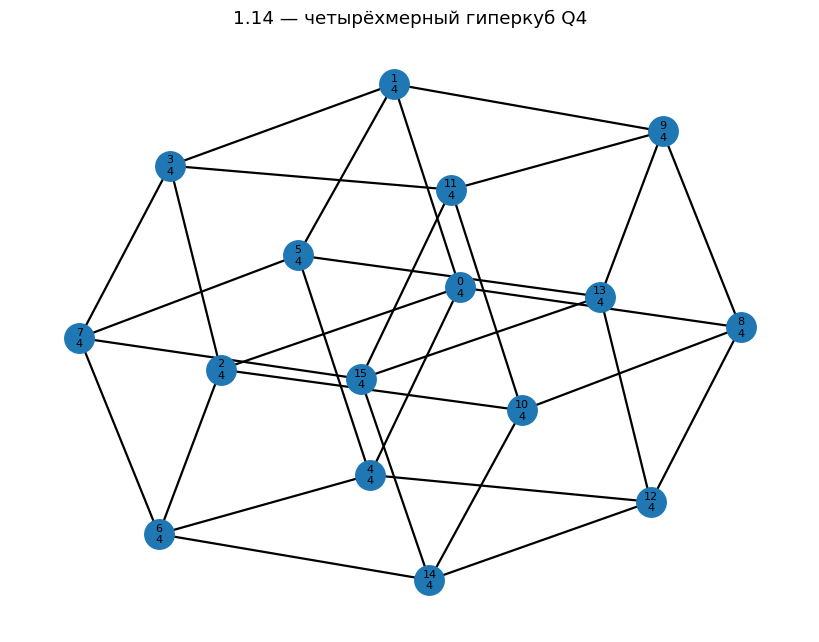


1.14 — полный граф K7
|V| = 7 |E| = 21
Степени: {0: 6, 1: 6, 2: 6, 3: 6, 4: 6, 5: 6, 6: 6}
Эйлеров граф: True
Эйлеров цикл:
[(0, 6), (6, 5), (5, 4), (4, 6), (6, 3), (3, 5), (5, 2), (2, 4), (4, 3), (3, 2), (2, 6), (6, 1), (1, 5), (5, 0), (0, 4), (4, 1), (1, 3), (3, 0), (0, 2), (2, 1), (1, 0)]


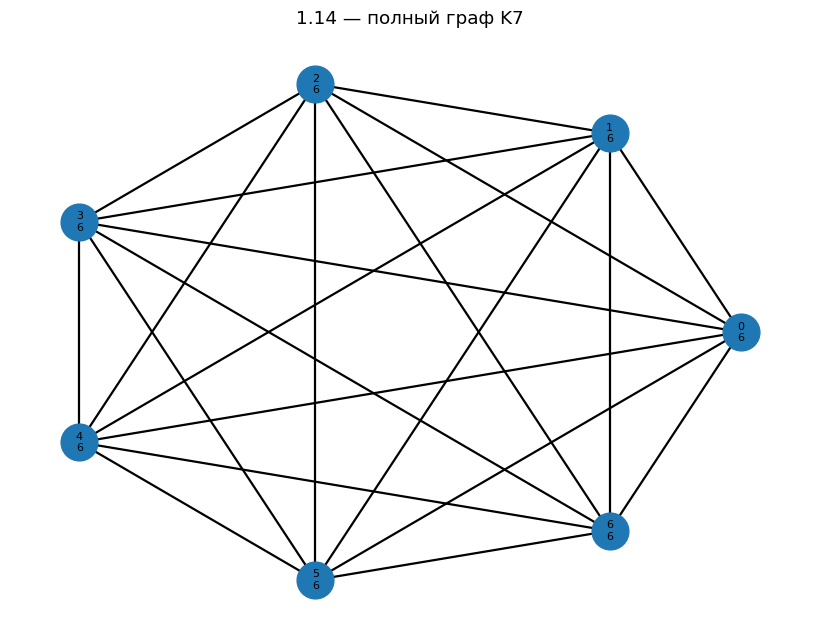

In [53]:
def show_euler_case(G, title, pos=None, node_size=800):
    print("\n" + title)
    print("|V| =", G.number_of_nodes(), "|E| =", G.number_of_edges())
    print("Степени:", dict(G.degree()))
    print("Эйлеров граф:", nx.is_eulerian(G))

    if nx.is_eulerian(G):
        cycle = list(nx.eulerian_circuit(G))
        print("Эйлеров цикл:")
        print(cycle)
    elif nx.has_eulerian_path(G):
        path = list(nx.eulerian_path(G))
        print("Эйлерова цикла нет, но есть эйлеров путь:")
        print(path)
    else:
        odd = [v for v, d in G.degree() if d % 2 == 1]
        print("Эйлерова цикла нет.")
        print("Вершины нечётной степени:", odd)

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(8, 6))
    labels = {v: f"{v}\n{G.degree(v)}" for v in G.nodes()}
    nx.draw(
        G,
        pos,
        with_labels=False,
        node_size=node_size,
        width=1.6
    )
    if G.number_of_nodes() <= 20:
        nx.draw_networkx_labels(G, pos, labels=labels, font_size=8)
    plt.title(title)
    plt.axis("off")
    plt.show()


# Большой граф a
G114_a = nx.Graph()
G114_a.add_edges_from([
    ("L", "Btm"),
    ("L", "TL"),
    ("TL", "C"),
    ("L", "C"),
    ("L", "TR"),
    ("TL", "TR"),
    ("TL", "R"),
    ("TR", "R"),
    ("TR", "C"),
    ("C", "R"),
    ("R", "Btm"),
])
pos_a = {
    "L": (-1.5, 0),
    "TL": (-0.6, 1.2),
    "TR": (0.6, 1.2),
    "R": (1.5, 0),
    "C": (0, -0.3),
    "Btm": (0, -1.7),
}
show_euler_case(G114_a, "1.14a", pos_a)


# Большой граф б
G114_b = nx.Graph()
G114_b.add_edges_from([
    ("a", "b"),
    ("b", "c"),
    ("c", "d"),
    ("d", "e"),
    ("e", "a"),
    ("a", "c"),
    ("e", "c"),
])
pos_b = {
    "a": (-1.1, 0),
    "b": (-0.3, 1.1),
    "c": (0.8, 0.2),
    "d": (0.5, -1.0),
    "e": (-0.6, -1.0),
}
show_euler_case(G114_b, "1.14б", pos_b)


# Большой граф в
G114_v = nx.Graph()
G114_v.add_edges_from([
    (1, 2), (2, 3), (3, 4), (4, 5), (5, 6), (6, 7), (7, 1),
    (1, 5),
    (7, 2), (7, 3), (7, 5),
    (6, 2), (6, 3), (6, 4),
])
pos_v = {
    1: (-0.7, 1.1),
    2: (0.6, 1.1),
    3: (1.5, 0.2),
    4: (1.15, -1.0),
    5: (-0.4, -1.4),
    6: (-1.2, -0.7),
    7: (-1.2, 0.4),
}
show_euler_case(G114_v, "1.14в", pos_v)


# Малый граф 1 с шестью вершинами
G114_small1 = nx.Graph()
G114_small1.add_edges_from([
    ("T", "UL"), ("T", "UR"),
    ("UL", "LL"), ("LL", "B"),
    ("B", "LR"), ("LR", "UR"),
    ("UL", "UR"), ("LL", "LR"),
    ("UL", "LR"), ("LL", "UR"),
])
pos_small1 = {
    "T": (0, 1.5),
    "UL": (-1, 0.7),
    "UR": (1, 0.7),
    "LL": (-1, -0.7),
    "LR": (1, -0.7),
    "B": (0, -1.5),
}
show_euler_case(G114_small1, "1.14 — малый граф 1", pos_small1)


# Малый граф 2 ("домик")
G114_small2 = nx.Graph()
G114_small2.add_edges_from([
    ("T", "UL"), ("T", "UR"),
    ("UL", "LL"), ("LL", "LR"), ("LR", "UR"),
    ("UL", "UR"),
    ("UL", "LR"), ("LL", "UR"),
])
pos_small2 = {
    "T": (0, 1.5),
    "UL": (-1, 0.5),
    "UR": (1, 0.5),
    "LL": (-1, -1),
    "LR": (1, -1),
}
show_euler_case(G114_small2, "1.14 — малый граф 2", pos_small2)


# Малый граф 3: прямоугольник с диагоналями, то есть K4
G114_small3 = nx.complete_graph(["UL", "UR", "LR", "LL"])
pos_small3 = {
    "UL": (-1, 1),
    "UR": (1, 1),
    "LR": (1, -1),
    "LL": (-1, -1),
}
show_euler_case(G114_small3, "1.14 — малый граф 3 (K4)", pos_small3)


# Граф додекаэдра со следующей страницы
G114_dodeca = nx.dodecahedral_graph()
show_euler_case(
    G114_dodeca,
    "1.14 — додекаэдральный граф",
    pos=nx.spring_layout(G114_dodeca, seed=3),
    node_size=350
)


# Четырёхмерный гиперкуб со следующей страницы
G114_q4 = nx.convert_node_labels_to_integers(nx.hypercube_graph(4))
show_euler_case(
    G114_q4,
    "1.14 — четырёхмерный гиперкуб Q4",
    pos=nx.spring_layout(G114_q4, seed=7),
    node_size=450
)


# Полный граф с 7 вершинами
G114_k7 = nx.complete_graph(7)
show_euler_case(
    G114_k7,
    "1.14 — полный граф K7",
    pos=nx.circular_layout(G114_k7),
    node_size=700
)

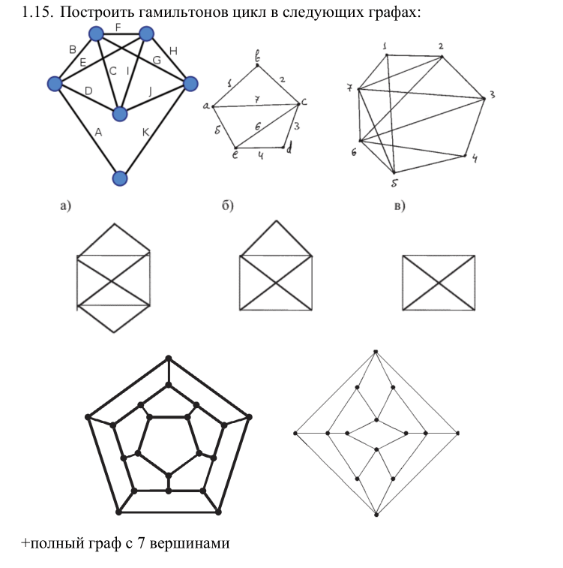

1.15 а
Гамильтонов цикл:
Btm -> L -> TL -> C -> TR -> R -> Btm


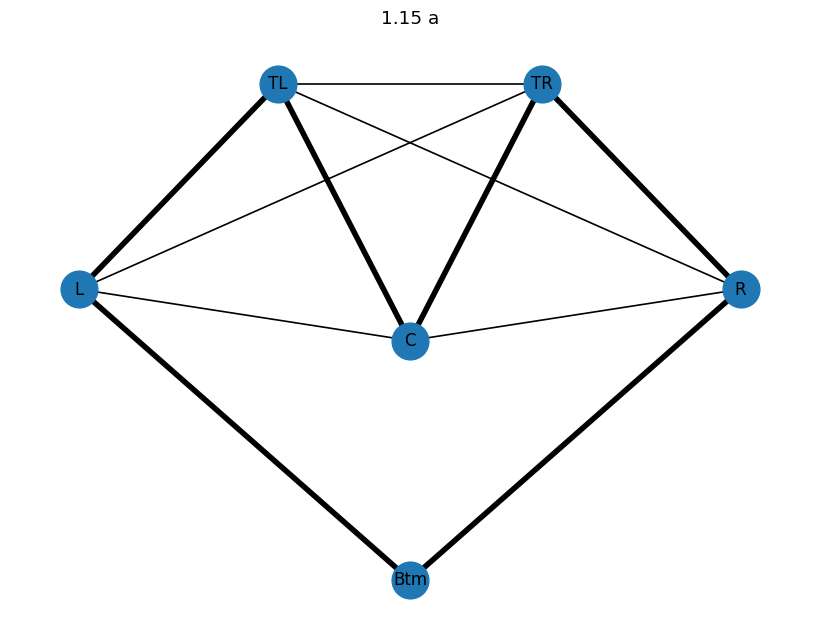

1.15 б
Гамильтонов цикл:
b -> a -> e -> d -> c -> b


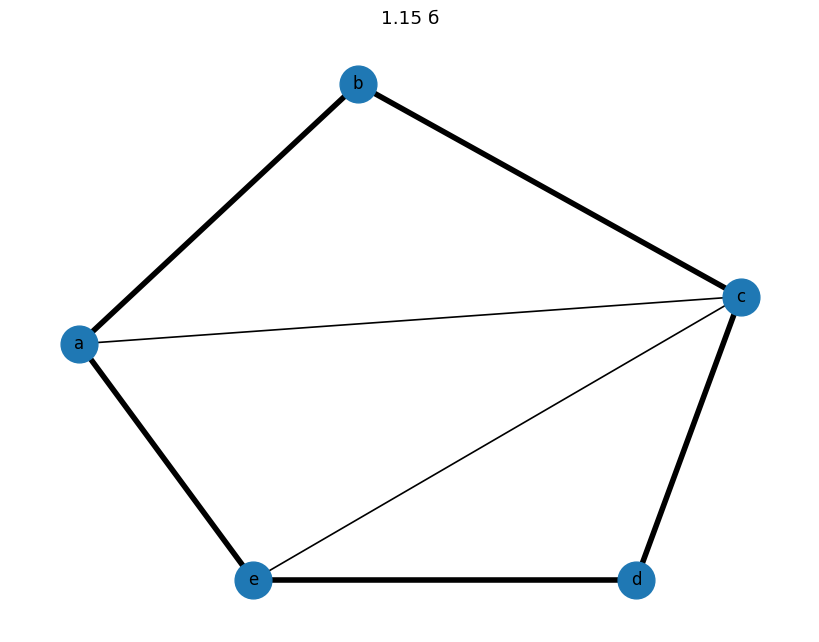

1.15 в
Гамильтонов цикл:
1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 7 -> 1


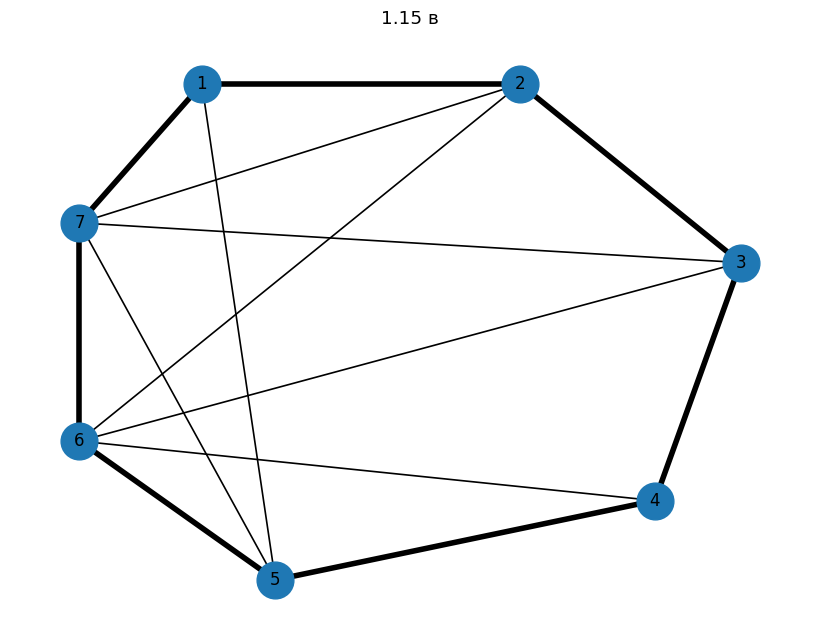

1.15 — малый граф 1
Гамильтонов цикл:
T -> UL -> LL -> B -> LR -> UR -> T


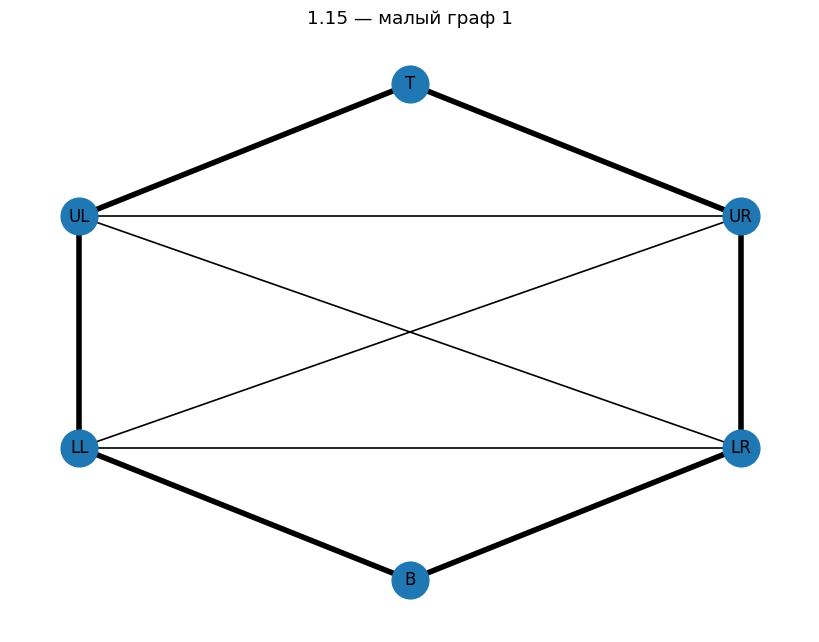

1.15 — малый граф 2
Гамильтонов цикл:
T -> UL -> LL -> LR -> UR -> T


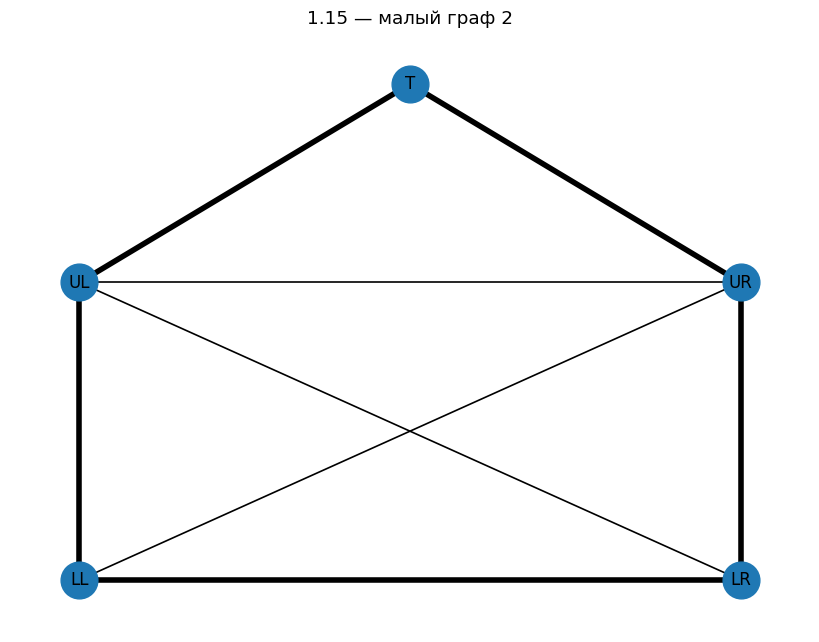

1.15 — малый граф 3
Гамильтонов цикл:
UL -> UR -> LR -> LL -> UL


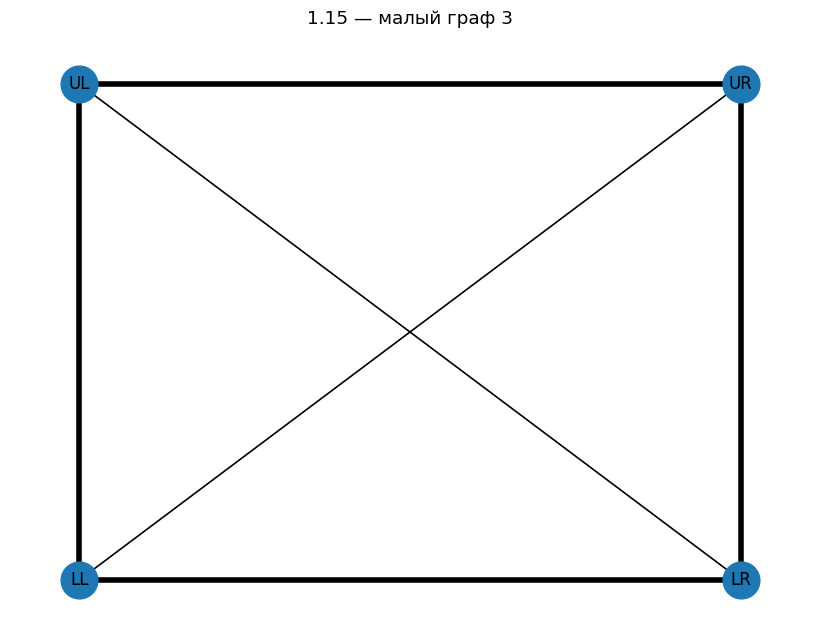

1.15 — додекаэдральный граф
Гамильтонов цикл:
0 -> 1 -> 2 -> 3 -> 19 -> 18 -> 17 -> 4 -> 5 -> 6 -> 7 -> 8 -> 9 -> 13 -> 14 -> 15 -> 16 -> 12 -> 11 -> 10 -> 0


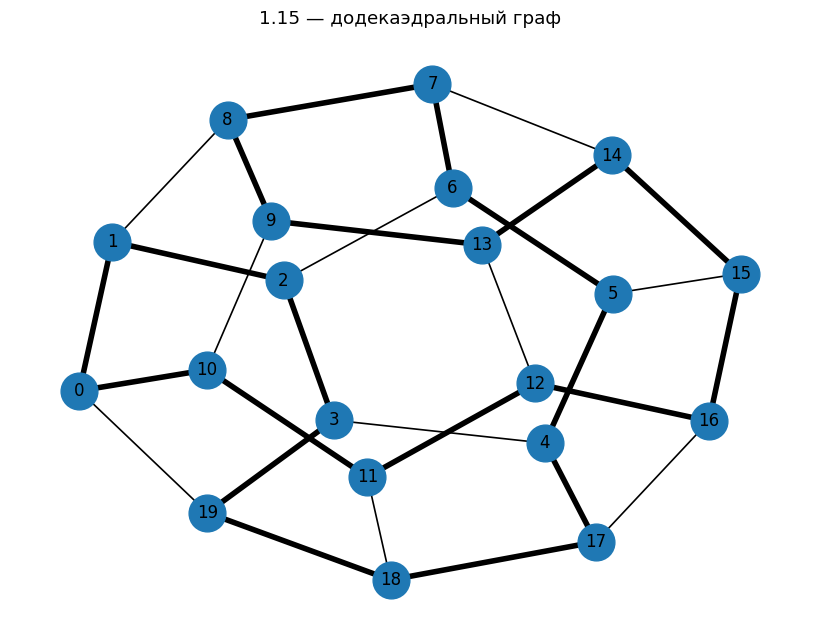

1.15 — четырёхмерный гиперкуб Q4
Гамильтонов цикл:
0 -> 8 -> 12 -> 4 -> 6 -> 2 -> 10 -> 14 -> 15 -> 7 -> 3 -> 11 -> 9 -> 13 -> 5 -> 1 -> 0


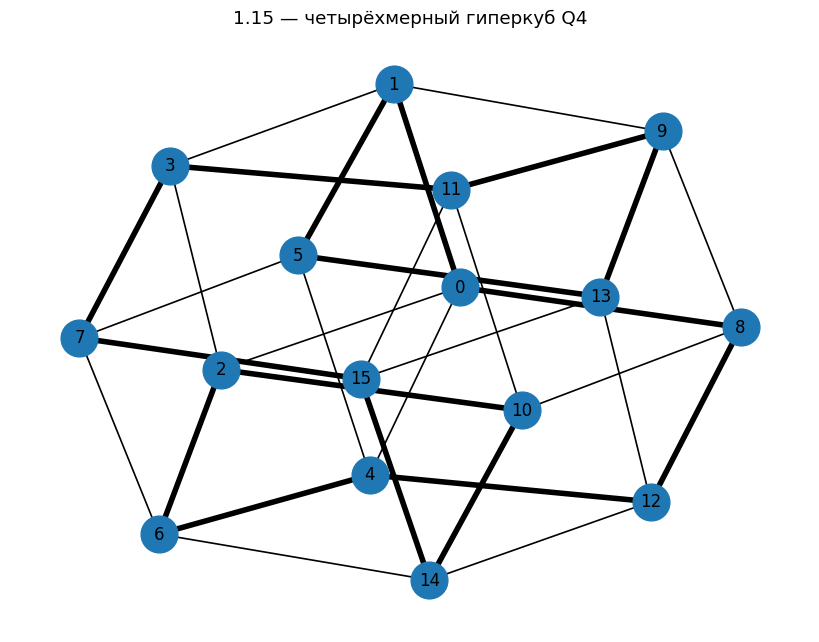

1.15 — полный граф K7
Гамильтонов цикл:
0 -> 1 -> 2 -> 3 -> 4 -> 5 -> 6 -> 0


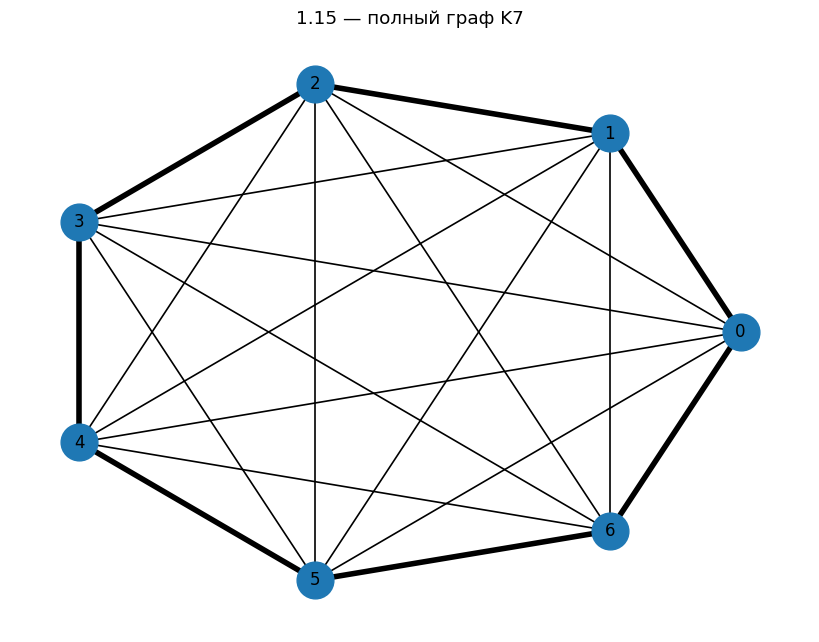

In [54]:
def find_hamiltonian_cycle(G):
    start = min(G.nodes(), key=lambda v: G.degree(v))
    n = G.number_of_nodes()

    path = [start]
    used = {start}

    def backtrack(v):
        if len(path) == n:
            if G.has_edge(v, start):
                return path + [start]
            return None

        candidates = [u for u in G.neighbors(v) if u not in used]
        candidates.sort(
            key=lambda u: sum(1 for w in G.neighbors(u) if w not in used)
        )

        for u in candidates:
            used.add(u)
            path.append(u)

            result = backtrack(u)
            if result is not None:
                return result

            path.pop()
            used.remove(u)

        return None

    return backtrack(start)


def show_hamiltonian_cycle(G, title, pos=None):
    cycle = find_hamiltonian_cycle(G)

    print(title)

    if cycle is None:
        print("Гамильтонов цикл не найден.")
    else:
        print("Гамильтонов цикл:")
        print(" -> ".join(map(str, cycle)))

    if pos is None:
        pos = nx.spring_layout(G, seed=42)

    plt.figure(figsize=(8, 6))

    nx.draw(
        G,
        pos,
        with_labels=True,
        node_size=700,
        width=1.2
    )

    if cycle is not None:
        cycle_edges = list(zip(cycle[:-1], cycle[1:]))

        nx.draw_networkx_edges(
            G,
            pos,
            edgelist=cycle_edges,
            width=4
        )

    plt.title(title)
    plt.axis("off")
    plt.show()


graphs_115 = [
    ("1.15 а", G114_a, pos_a),
    ("1.15 б", G114_b, pos_b),
    ("1.15 в", G114_v, pos_v),
    ("1.15 — малый граф 1", G114_small1, pos_small1),
    ("1.15 — малый граф 2", G114_small2, pos_small2),
    ("1.15 — малый граф 3", G114_small3, pos_small3),
    (
        "1.15 — додекаэдральный граф",
        G114_dodeca,
        nx.spring_layout(G114_dodeca, seed=3)
    ),
    (
        "1.15 — четырёхмерный гиперкуб Q4",
        G114_q4,
        nx.spring_layout(G114_q4, seed=7)
    ),
    (
        "1.15 — полный граф K7",
        G114_k7,
        nx.circular_layout(G114_k7)
    ),
]

for title, G, pos in graphs_115:
    show_hamiltonian_cycle(G, title, pos)